# GameTheory 15d - Valeur de Shapley de groupe : évaluer une équipe, pas une somme d'individus (Rust)

**Navigation** : [<< 15-CooperativeGames (track principal)](GameTheory-15-CooperativeGames-Python.ipynb) | [Index](README.md) | [15d Python (jumeau complet) <<](GameTheory-15d-Shapley-Groupes-Python.ipynb)

**Kernel** : `rust` (evcxr)

**Article distillé** : Flores R., Molina E., Tejada J. (2019). *Evaluating groups with the generalized Shapley value*. 4OR 17(2):141-172. doi:[10.1007/s10288-018-0380-8](https://doi.org/10.1007/s10288-018-0380-8)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :

1. Définir la **valeur de Shapley de groupe** $\varphi^g(C)$ comme la valeur du mandataire dans le **jeu fusionné** de Lehrer
2. Distinguer l'axiome **G-SPB** (« une seule voix ») du réflexe additif $\sum_i \varphi_i$
3. Décomposer l'arrivée d'un nouveau membre avec le **théorème 2** : indépendance + complémentarité
4. Énumérer des coalitions par **masques de bits** (`u64`) et calculer en arithmétique **exacte** (`Ratio<i64>`)
5. Estimer $\varphi^g$ par **Monte Carlo** avec un RNG seedé (`StdRng`) quand $2^n$ dépasse toute énumération

**Durée estimée** : ~15 min | **Prérequis** : [GameTheory-15 CooperativeGames](GameTheory-15-CooperativeGames-Python.ipynb) (valeur de Shapley, axiomes) | **Lien** : jumeau complet [GameTheory-15d Python](GameTheory-15d-Shapley-Groupes-Python.ipynb)

***

Un décideur doit choisir **k agents** : former un binôme, recruter une équipe, cibler un groupe dans un réseau. Le réflexe est de calculer la valeur de Shapley de chacun et de garder les k meilleurs. Ce réflexe suppose que la valeur d'un groupe est la **somme** des valeurs de ses membres.

Ce carnet montre, calcul exact à l'appui, que cette hypothèse se trompe dès que les agents sont **redondants** (ils apportent la même chose) ou **complémentaires** (l'un rend l'autre utile). L'objet de mesure correct est la **valeur de Shapley de groupe** $\varphi^g(C)$ — la valeur de Shapley généralisée de Marichal, Kojadinovic et Fujimoto (2007), axiomatisée et appliquée à la sélection de groupes par Flores, Molina et Tejada.

| Section | Contenu |
|---|---|
| 1-2 | L'organe Rust, le jeu fusionné de Lehrer, la définition de $\varphi^g$, l'axiome G-SPB |
| 3 | L'exemple 1 de l'article, reproduit en arithmétique exacte, et le théorème 2 |
| 4 | Complémentarité moyenne et profitabilité d'un groupe |
| 5 | Réseau des mariages florentins (Padgett) : calcul exact sur $2^{15}$ coalitions |
| 6 | Estimation Monte Carlo : calibration, puis club de karaté de Zachary ($2^{34}$ coalitions) |
| 7 | Exercices |

## Table des matières

1. [L'organe : du module Python au Rust pur](#1-lorgane--du-module-python-au-rust-pur)
2. [Le jeu fusionné et l'axiome G-SPB](#2-le-jeu-fusionne-et-laxiome-g-spb)
3. [Exemple 1 et théorème 2](#3-exemple-1-et-theoreme-2)
4. [Complémentarité et profitabilité](#4-complementarite-et-profitabilite)
5. [Les familles de Florence](#5-les-familles-de-florence)
6. [Monte Carlo : quand $2^n$ explose](#6-monte-carlo--quand-2n-explose)
7. [Exercices](#7-exercices)

## References

- Flores R., Molina E., Tejada J. (2019). *Evaluating groups with the generalized Shapley value*. 4OR 17(2):141-172.
- Marichal J.-L., Kojadinovic I., Fujimoto K. (2007). *Axiomatizations and properties of the generalized Shapley value*.
- Castro J., Gómez D., Tejada J. (2009). *Polynomial calculation of the Shapley value based on sampling*. Applied Mathematics and Computation 216(2):519-529.
- Padgett J.F., Ansell C.K. (1993). *Robust Action and the Rise of the Medici*. American Journal of Sociology 98(6):1259-1319.
- Zachary W.W. (1977). *An Information Flow Model for Conflict and Fission in Small Groups*. Journal of Anthropological Research 33(4):452-473.
- [Crate num-rational (crates.io)](https://crates.io/crates/num-rational) · [Crate rand](https://crates.io/crates/rand) · [Crate plotters](https://crates.io/crates/plotters)
- [evcxr — le kernel Jupyter pour Rust](https://github.com/evcxr/evcxr)

## 1. L'organe : du module Python au Rust pur

Le jumeau Python repose sur trois piliers : le module maison `cooperative_games/group_value.py` (table des $2^n$ valeurs, Shapley exact en `Fraction`, valeur de groupe, décomposition du théorème 2), `networkx` (graphes florentin et karaté, centralité d'intermédiarité) et `numpy` / `matplotlib`. En Rust sous evcxr, l'organe change de nature : il n'existe **aucune crate CooperativeGames** et la carte d'écosystème du dépôt ([rust-ecosystem-map.md](../../docs/reference/rust-ecosystem-map.md)) ne référence pas d'équivalent — la sémantique tient en une trentaine de lignes de masques binaires et de `Ratio<i64>`, et c'est précisément le sujet de ce carnet. **Copie pédagogique déclarée**, motif : le carnet enseigne ces formules, les réimplémenter lisiblement en Rust est l'exercice.

| Besoin du jumeau Python | Choix Rust | Licence |
|---|---|---|
| `fractions.Fraction` (arithmétique exacte) | crate `num-rational` (`Ratio<i64>`) | MIT + Apache-2.0 |
| `numpy.random.default_rng` (Monte Carlo graine par graine) | crate `rand` (`StdRng::seed_from_u64`, `partial_shuffle`) | MIT + Apache-2.0 |
| `networkx` (graphes, Brandes, degrés) | **aucune crate** : listes d'adjacence `Vec<Vec<usize>>` + Brandes écrit à la main | std pur |
| `matplotlib` (figures) | crate `plotters` en SVG, sans texte (`features = ["evcxr", "line_series"]`, pas de police système) | MIT |

Le témoin négatif de cette réimplémentation est double : les **valeurs publiées de l'article** de Flores, Molina et Tejada (2019), et les **sorties committées du jumeau Python**, qui reste l'oracle numérique de la série. Les données embarquées (arêtes de l'exemple 1, familles florentines, club de karaté) sont reprises telles quelles du jumeau, en listes `const` indexées à partir de 0.

In [2]:
// L'unique cellule :dep du carnet, en tete (convention evcxr du depot) :
// un :dep plus bas recompilerait tout et effacerait les variables persistees.
:dep num-rational = "0.4"
:dep rand = "0.8"
:dep plotters = { version = "0.3", default-features = false, features = ["evcxr", "line_series"] }

println!("Crates : num-rational 0.4 (Ratio<i64>), rand 0.8 (StdRng graine par graine), plotters 0.3 (SVG sans ttf)");

Crates : num-rational 0.4 (Ratio<i64>), rand 0.8 (StdRng graine par graine), plotters 0.3 (SVG sans ttf)


## 2. Le jeu fusionné et l'axiome G-SPB

### 2.1 Fusionner un groupe en un mandataire

La **valeur de groupe de Shapley** (Flores, Molina et Tejada, 2019 ; généralisation de Marichal, Kojadinovic et Fujimoto, 2007) évalue une coalition $C$ comme une **unité** : on fusionne ses membres en un seul joueur, le **mandataire**, et on lui attribue sa valeur de Shapley dans le jeu fusionné $(N_C, v_C)$ de Lehrer (1988). Remplacer $c$ joueurs par un seul acteur fait passer le jeu de $n$ joueurs à $m = n - c + 1$ acteurs :

$$\varphi^g(C) = \sum_{T \subseteq N \setminus C} \frac{t!\,(m-t-1)!}{m!}\,\bigl(v(T \cup C) - v(T)\bigr), \qquad t = |T|.$$

Le jeu de référence est le **jeu de connectivité** d'Amer et Gimenez (2004) : sur un graphe non orienté, $v(S) = 1$ si $|S| \geq 2$ et si le sous-graphe induit par $S$ est connexe, $0$ sinon. Tout se calcule en **arithmétique exacte** : une coalition est un masque `u64` (bit $i$ = joueur $i$), la connexité se teste par un parcours en profondeur, et les coefficients de Shapley sont des `Ratio<i64>` — les factorielles jusqu'à $15!$ tiennent dans un `i64` ($1{,}3 \times 10^{12} < 9{,}2 \times 10^{18}$).

La cellule suivante construit l'exemple 1 de l'article (sommets 1 à 9), fusionne $C = \{4, 5\}$ et vérifie la formule directe **contre** le calcul explicite du Shapley du mandataire dans le jeu fusionné $(N_C, v_C)$ : les deux voies doivent donner le même rationnel.

In [3]:
{
    // Code 2.1 - Jeu fusionne pour C = {4, 5} : deux voies vers phi_g.
    // (Cellule autonome : sous evcxr les fonctions ne persistent pas d'une cellule a l'autre,
    // les utilitaires sont donc redefinis dans chaque cellule qui les utilise.)
    use num_rational::Ratio;
    type R = Ratio<i64>;

    // Exemple 1 de l'article : sommets 1 a 9, indices 0 a 8 en interne.
    const ARETES1: [(usize, usize); 8] = [
        (0, 3), (1, 3), (2, 3), (3, 4), (4, 5), (5, 6), (5, 7), (5, 8),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    // Jeu de connectivite d'Amer-Gimenez : v(S) = 1 si |S| >= 2 et S connexe, 0 sinon.
    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn fact(k: i64) -> i64 {
        if k <= 1 { 1 } else { (2..=k).product() }
    }

    let adj1 = voisins(9, &ARETES1);
    let v1 = move |s: u64| connexe(s, &adj1);

    // Fusion de C = {4, 5} (indices 3, 4) : m = n - c + 1 = 8 acteurs, le mandataire
    // porte le numero d'acteur 7, les acteurs 0 a 6 sont les joueurs 1, 2, 3, 6, 7, 8, 9.
    let (n, m) = (9usize, 8i64);
    let groupe: u64 = (1u64 << 3) | (1u64 << 4);
    let hors_idx: [usize; 7] = [0, 1, 2, 5, 6, 7, 8];
    let noms: [&str; 8] = ["1", "2", "3", "6", "7", "8", "9", "{4, 5}"];
    println!("Joueurs du jeu fusionne N_C : {:?}", noms);
    println!("n = {} joueurs, c = 2 -> m = {} acteurs apres fusion de {{4, 5}}", n, m);

    // v_C(S) = v((S sans le mandataire, traduit) u C) si le mandataire est dans S, sinon v(S traduit).
    // Generique en F (et non &dyn Fn) : evcxr exigerait sinon une closure 'static, impossible ici.
    fn vc<F: Fn(u64) -> i64>(acteurs: u64, hors_idx: &[usize], mandataire: usize, groupe: u64, v: &F) -> i64 {
        let mut masque = 0u64;
        for (k, &orig) in hors_idx.iter().enumerate() {
            if (acteurs >> k) & 1 == 1 {
                masque |= 1u64 << orig;
            }
        }
        if (acteurs >> mandataire) & 1 == 1 {
            v(masque | groupe)
        } else {
            v(masque)
        }
    }
    let position = move |nom: &str| noms.iter().position(|&x| x == nom).unwrap();
    let tests: Vec<&[&str]> = vec![
        &["{4, 5}"], &["{4, 5}", "6"], &["{4, 5}", "7"], &["7", "8"], &["6", "7"],
    ];
    for coalition in &tests {
        let mut acteurs = 0u64;
        for nom in *coalition {
            acteurs |= 1u64 << position(nom);
        }
        println!("  v_C({}) = {}", coalition.join(", "), vc(acteurs, &hors_idx, 7, groupe, &v1));
    }

    // Voie A : Shapley du mandataire dans le jeu fusionne (N_C, v_C), sur les 128 sous-ensembles des 7 autres acteurs.
    let mut shapley_mandataire = R::from_integer(0);
    let mut t = 0u64;
    loop {
        let taille = t.count_ones() as i64;
        let coef = R::new(fact(taille) * fact(m - taille - 1), fact(m));
        let delta = vc(t | (1u64 << 7), &hors_idx, 7, groupe, &v1) - vc(t, &hors_idx, 7, groupe, &v1);
        shapley_mandataire += coef * R::from_integer(delta);
        if t == 127 { break; }
        t += 1;
    }

    // Voie B : formule directe sur les masques originaux, en enumerant N \ C par decrements de masque.
    let mut directe = R::from_integer(0);
    let hors = ((1u64 << n) - 1) & !groupe;
    let mut sous = hors;
    loop {
        let taille = sous.count_ones() as i64;
        let coef = R::new(fact(taille) * fact(m - taille - 1), fact(m));
        directe += coef * R::from_integer(v1(sous | groupe) - v1(sous));
        if sous == 0 { break; }
        sous = (sous - 1) & hors;
    }
    println!("Shapley du mandataire dans (N_C, v_C) : {}", shapley_mandataire);
    println!("Formule directe phi_g({{4, 5}})         : {}", directe);
}


Joueurs du jeu fusionne N_C : ["1", "2", "3", "6", "7", "8", "9", "{4, 5}"]


n = 9 joueurs, c = 2 -> m = 8 acteurs apres fusion de {4, 5}


  v_C({4, 5}) = 1


  v_C({4, 5}, 6) = 1


  v_C({4, 5}, 7) = 0


  v_C(7, 8) = 0


  v_C(6, 7) = 1


Shapley du mandataire dans (N_C, v_C) : 187/280


Formule directe phi_g({4, 5})         : 187/280


()

### Lecture du résultat : les deux voies coincident

Le jeu fusionne se lit directement sur les evaluations imprimees : le mandataire {4, 5} seul vaut 1 (4 et 5 sont adjacents), avec 6 il vaut encore 1, mais avec 7 il retombe a 0 : la coalition {4, 5, 7} n'est pas connexe puisque 7 ne pend qu'au centre 6, absent du groupe. Les coalitions {7, 8} (sans le mandataire) et {6, 7} valent respectivement 0 et 1, comme dans le graphe d'origine.

Les deux voies de calcul donnent **187/280**, exactement la valeur publiee dans l'article pour le binome {4, 5} : la valeur de Shapley du mandataire dans le jeu fusionne (voie A) et la formule directe sommant sur les sous-ensembles de N \ C (voie B) sont deux ecritures du meme nombre. La suite du carnet utilise la voie B, plus simple a porter : elle n'a pas besoin de traduire les coalitions d'acteurs en masques originaux.

A noter l'arithmetique : tous les calculs sont menes en `Ratio<i64>`, donc **exactement**, comme le `Fraction` du carnet Python. Le plus grand denominateur rencontre dans ce carnet est 15! (environ 1,3 x 10^12), tres en deca de la capacite d'un `i64`.

### 2.2 L'axiome G-SPB et le théorème 1 : un groupe, une voix

Quelle propriété distingue la valeur de groupe d'une simple somme de valeurs individuelles ? L'article isole l'axiome **G-SPB** (*Group Symmetry-Proxy Balance*, symétrie et équilibre autour du mandataire) : dans un jeu d'unanimité $u_N$ (qui vaut 1 si et seulement si la coalition contient **tous** les joueurs), les joueurs extérieurs au groupe doivent conserver la même valeur entre eux, et la répartition entre le groupe et chacun des autres ne doit dépendre que du **nombre** d'acteurs après fusion, pas de la taille du groupe.

Le **théorème 1** en tire une formule close, valable dans le jeu d'unanimité $u_N$ à $n$ joueurs pour un groupe $C$ de taille $c$ :

$$\varphi^g(C) = \frac{1}{n-c+1} \qquad \text{alors que la valeur additive donne} \qquad \sum_{i \in C} \varphi_i = \frac{c}{n}.$$

L'écart mesure exactement ce que la fusion change : un groupe de $c$ joueurs pèse **une voix** parmi $m = n-c+1$ acteurs, et non $c$ voix parmi $n$. Le code ci-dessous vérifie la formule en arithmétique exacte pour $n = 6$ et toutes les tailles de groupe, et la compare à la valeur additive.

In [4]:
{
    // Code 2.2 - Theoreme 1 sur le jeu d'unanimite u_N : phi_g = 1/(n-c+1) contre c/n en additif.
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use num_rational::Ratio;
    type R = Ratio<i64>;

    fn fact(k: i64) -> i64 {
        if k <= 1 { 1 } else { (2..=k).product() }
    }

    // Formule directe : phi_g(C) = somme sur T inclus dans N\C de t!(m-t-1)!/m! * (v(T u C) - v(T)).
    // Generique en F (et non &dyn Fn) : evcxr exigerait sinon une closure 'static, impossible ici.
    fn phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64) -> R {
        let c = groupe.count_ones() as i64;
        let m = n as i64 - c + 1;
        let hors = ((1u64 << n) - 1) & !groupe;
        let mut total = R::from_integer(0);
        let mut sous = hors;
        loop {
            let t = sous.count_ones() as i64;
            let coef = R::new(fact(t) * fact(m - t - 1), fact(m));
            total += coef * R::from_integer(v(sous | groupe) - v(sous));
            if sous == 0 { break; }
            sous = (sous - 1) & hors;
        }
        total
    }

    let n = 6usize;
    let plein = (1u64 << n) - 1;
    // Jeu d'unanimite u_N : 1 si et seulement si S = N.
    let u_n = move |s: u64| (s == plein) as i64;

    println!("{:>4}  {:>10}  {:>10}  {:>10}", "c", "phi_g exact", "phi_g reel", "c/n additif");
    for c in 1..=n {
        let groupe = (1u64 << c) - 1; // les c premiers joueurs
        let phi_g = phi_groupe(n, &u_n, groupe);
        let additif = R::new(c as i64, n as i64);
        let reel = *phi_g.numer() as f64 / *phi_g.denom() as f64;
        let reel_add = *additif.numer() as f64 / *additif.denom() as f64;
        println!("{:>4}  {:>10}  {:>10.4}  {:>10.4}", c, phi_g, reel, reel_add);
    }
    println!("\nAttendu (theoreme 1) : phi_g = 1/(n-c+1) ; la somme additive c/n surestime le groupe des que c >= 2.");
}


   c  phi_g exact  phi_g reel  c/n additif


   1         1/6      0.1667      0.1667


   2         1/5      0.2000      0.3333


   3         1/4      0.2500      0.5000


   4         1/3      0.3333      0.6667


   5         1/2      0.5000      0.8333


   6           1      1.0000      1.0000


Attendu (theoreme 1) : phi_g = 1/(n-c+1) ; la somme additive c/n surestime le groupe des que c >= 2.


()

### Lecture du résultat : une voix par acteur, pas par joueur

Le tableau confirme le théorème 1 au terme près, en fractions exactes : pour $n = 6$, un singleton vaut $1/6$ (la fusion ne change rien), un binôme vaut $1/5$, un trio $1/4$, ..., et le groupe de tous les joueurs vaut $1$. La colonne de droite montre la valeur additive $c/n$ : $1/3$ pour un binôme, $1/2$ pour un trio.

L'écart est systématique et **négatif** : dans le jeu d'unanimité, la fusion fait toujours perdre de la valeur au groupe ($1/(n-c+1) < c/n$ dès que $c \ge 2$). L'intuition est celle du vote : réunir $c$ joueurs en un seul mandataire réduit le nombre d'acteurs dont la présence est indispensable, donc le poids du bloc. Le phénomène s'inversera dans les jeux de connectivité des sections suivantes, où la fusion peut au contraire **créer** de la valeur quand le groupe devient un passage obligé.

## 3. L'exemple 1 de l'article, en arithmétique exacte

### 3.1 Le meilleur binôme n'est pas celui des deux meilleurs individus

Le graphe de l'exemple 1 est une **« double étoile »** à 9 sommets : les feuilles 1, 2, 3 pendent au centre 4 ; les feuilles 7, 8, 9 pendent au centre 6 ; et le sommet 5 relie les deux centres (arêtes 4-5 et 5-6). Le sommet 5 est donc un **pont** : sans lui, le graphe se coupe en deux étoiles disjointes.

```
1, 2, 3            7, 8, 9
   \ | /              \ | /
     4 ----- 5 ----- 6
```

Le code calcule les neuf valeurs de Shapley individuelles en fractions exactes (multipliées par 360 pour les lire comme des entiers), puis classe les 36 binômes par valeur de groupe $\varphi^g$. La question posée : le meilleur binôme est-il celui des deux meilleurs individus ?

In [5]:
{
    // Code 3.1 - Valeurs individuelles et classement exact des 36 binomes de l'exemple 1.
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use num_rational::Ratio;
    type R = Ratio<i64>;

    const ARETES1: [(usize, usize); 8] = [
        (0, 3), (1, 3), (2, 3), (3, 4), (4, 5), (5, 6), (5, 7), (5, 8),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn fact(k: i64) -> i64 {
        if k <= 1 { 1 } else { (2..=k).product() }
    }

    fn phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64) -> R {
        let c = groupe.count_ones() as i64;
        let m = n as i64 - c + 1;
        let hors = ((1u64 << n) - 1) & !groupe;
        let mut total = R::from_integer(0);
        let mut sous = hors;
        loop {
            let t = sous.count_ones() as i64;
            let coef = R::new(fact(t) * fact(m - t - 1), fact(m));
            total += coef * R::from_integer(v(sous | groupe) - v(sous));
            if sous == 0 { break; }
            sous = (sous - 1) & hors;
        }
        total
    }

    let f = |r: &R| *r.numer() as f64 / *r.denom() as f64;
    let adj1 = voisins(9, &ARETES1);
    let v1 = move |s: u64| connexe(s, &adj1);

    // Valeurs individuelles : phi_i = phi_g({i}).
    let phi_exact: Vec<R> = (0..9).map(|i| phi_groupe(9, &v1, 1u64 << i)).collect();
    let fois_360: Vec<i64> = phi_exact.iter().map(|p| (p * R::from_integer(360)).to_integer()).collect();
    println!("360 * phi_i : {:?}", fois_360);

    // Les 36 binomes, tries par phi_g decroissant (puis par indices croissants pour departager).
    let mut binomes: Vec<((usize, usize), R, R)> = Vec::new();
    for a in 0..9 {
        for b in (a + 1)..9 {
            let g = phi_groupe(9, &v1, (1u64 << a) | (1u64 << b));
            let add = phi_exact[a] + phi_exact[b];
            binomes.push(((a + 1, b + 1), g, add));
        }
    }
    binomes.sort_by(|x, y| y.1.cmp(&x.1).then(x.0.cmp(&y.0)));

    println!("\n{:>4}  {:>8}  {:>10}  {:>9}", "rang", "binome", "phi_g", "additive");
    for (rang, (paire, g, a)) in binomes.iter().take(5).enumerate() {
        println!("{:>4}  {:>8}  {:>10}  {:>9.4}", rang + 1, format!("{:?}", paire), g, f(a));
    }
    let rang_46 = binomes.iter().position(|r| r.0 == (4, 6)).unwrap() + 1;
    let phi_46 = phi_groupe(9, &v1, (1u64 << 3) | (1u64 << 5));
    println!("\nBinome des deux meilleurs individus (4, 6) : phi_g = {}, rang {} sur 36", phi_46, rang_46);
}


360 * phi_i : [-8, -8, -8, 139, 130, 139, -8, -8, -8]


rang    binome       phi_g   additive


   1    (4, 5)     187/280     0.7472


   2    (5, 6)     187/280     0.7472


   3    (4, 6)         1/2     0.7722


   4    (1, 4)     131/280     0.3639


   5    (2, 4)     131/280     0.3639


Binome des deux meilleurs individus (4, 6) : phi_g = 1/2, rang 3 sur 36


()

### Lecture du résultat : reproduction exacte, et un classement qui s'inverse

Les valeurs individuelles reproduisent **exactement** celles de l'article : $360\,\varphi_i = -8$ pour les six feuilles, $139$ pour les centres 4 et 6, $130$ pour le pont 5. Les feuilles ont une valeur négative : ajoutée à un centre isolé, une feuille crée une paire connexe (+1), mais ajoutée à une coalition connexe qui ne contient pas son centre, elle la déconnecte.

Au classement individuel, le meilleur binôme serait $\{4, 6\}$ (valeur additive $278/360 \approx 0.772$). Au classement par valeur de groupe, il vaut **1/2** et n'arrive qu'au troisième rang (dernière ligne), derrière les binômes centre + pont $\{4, 5\}$ et $\{5, 6\}$ qui valent **187/280**, là encore la valeur publiée. Les deux centres sont redondants : aucun ne rend l'autre plus utile, puisqu'ils ne sont pas adjacents et qu'il faut le pont 5 pour les relier.

### 3.2 Le théorème 2 : indépendance plus complémentarité

La **complémentarité moyenne** de deux joueurs (définition 3) moyenne leur différence d'ordre 2, qui mesure combien la présence de $i$ augmente l'apport de $j$ :

$$\psi_{ij}(N, v) = \sum_{S \subseteq N \setminus \{i,j\}} \frac{s!\,(n-s-1)!}{n!}\,\Delta^2_{ij}(S), \qquad \Delta^2_{ij}(S) = v(S \cup \{i,j\}) - v(S \cup \{i\}) - v(S \cup \{j\}) + v(S).$$

Le **théorème 2** décompose l'apport d'un nouveau membre $i$ à un groupe $C$ en deux termes :

$$\varphi^g(C \cup \{i\}) - \varphi^g(C) = \underbrace{\varphi_i(N \setminus C,\, v_{\vert N \setminus C})}_{\text{valeur de } i \text{ sans le groupe}} + \underbrace{\psi_{ci}(N_C, v_C)}_{\text{complémentarité avec le groupe}}.$$

Le premier terme est la valeur de Shapley **restreinte** : celle de $i$ dans le sous-jeu où le groupe $C$ est retiré. Le second est la complémentarité entre $i$ et le mandataire dans le jeu fusionné. Le code vérifie cette décomposition sur les deux binômes de l'exemple, avec le centre 4 comme membre initial.

In [6]:
{
    // Code 3.2 - Decomposition du theoreme 2 sur l'exemple 1 (groupe initial C = {4}).
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use num_rational::Ratio;
    type R = Ratio<i64>;

    const ARETES1: [(usize, usize); 8] = [
        (0, 3), (1, 3), (2, 3), (3, 4), (4, 5), (5, 6), (5, 7), (5, 8),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn fact(k: i64) -> i64 {
        if k <= 1 { 1 } else { (2..=k).product() }
    }

    // Generique en F (et non &dyn Fn) : evcxr exigerait sinon une closure 'static, impossible ici.
    fn phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64) -> R {
        let c = groupe.count_ones() as i64;
        let m = n as i64 - c + 1;
        let hors = ((1u64 << n) - 1) & !groupe;
        let mut total = R::from_integer(0);
        let mut sous = hors;
        loop {
            let t = sous.count_ones() as i64;
            let coef = R::new(fact(t) * fact(m - t - 1), fact(m));
            total += coef * R::from_integer(v(sous | groupe) - v(sous));
            if sous == 0 { break; }
            sous = (sous - 1) & hors;
        }
        total
    }

    // Shapley restreint : valeur de j dans le sous-jeu ou le groupe C est retire.
    // Les joueurs du sous-jeu sont N\C (j en fait partie, nn = |N\C|) ;
    // la somme porte sur les sous-ensembles de (N\C)\{j}.
    fn shapley_restreint<F: Fn(u64) -> i64>(n: usize, v: &F, j: usize, groupe: u64) -> R {
        let hors = ((1u64 << n) - 1) & !groupe;
        let autres = hors & !(1u64 << j);
        let nn = autres.count_ones() as i64 + 1;
        let mut total = R::from_integer(0);
        let mut sous = autres;
        loop {
            let s = sous.count_ones() as i64;
            let coef = R::new(fact(s) * fact(nn - s - 1), fact(nn));
            let delta = v(sous | (1u64 << j)) - v(sous);
            total += coef * R::from_integer(delta);
            if sous == 0 { break; }
            sous = (sous - 1) & autres;
        }
        total
    }

    // Complementarite moyenne psi_ij(N, v) : moyenne de la difference d'ordre 2.
    fn complementarite<F: Fn(u64) -> i64>(n: usize, v: &F, i: usize, j: usize) -> R {
        let plein = (1u64 << n) - 1;
        let autres = plein & !(1u64 << i) & !(1u64 << j);
        let mut total = R::from_integer(0);
        let mut sous = autres;
        loop {
            let s = sous.count_ones() as i64;
            let coef = R::new(fact(s) * fact(n as i64 - s - 1), fact(n as i64));
            let delta2 = v(sous | (1u64 << i) | (1u64 << j)) - v(sous | (1u64 << i))
                - v(sous | (1u64 << j)) + v(sous);
            total += coef * R::from_integer(delta2);
            if sous == 0 { break; }
            sous = (sous - 1) & autres;
        }
        total
    }

    let adj1 = voisins(9, &ARETES1);
    let v1 = move |s: u64| connexe(s, &adj1);
    let c4: u64 = 1u64 << 3; // C = {4}, indice 3
    let phi4 = phi_groupe(9, &v1, c4);

    println!("{:>7}  {:>7}  {:>10}  {:>7}  {:>7}  {:>7}", "binome", "phi_4", "phi_j(N-4)", "psi_4j", "somme", "phi_g");
    for j in [6usize, 5usize] {
        let indep = shapley_restreint(9, &v1, j - 1, c4);
        let compl = complementarite(9, &v1, 3, j - 1);
        let total = phi4 + indep + compl;
        let phi_g = phi_groupe(9, &v1, c4 | (1u64 << (j - 1)));
        println!("  (4, {})  {:>7}  {:>10}  {:>7}  {:>7}  {:>7}", j, phi4, indep, compl, total, phi_g);
    }
    println!("\nLe theoreme 2 est verifie : la somme phi_4 + independance + complementarite redonne phi_g au terme pres.");
}


 binome    phi_4  phi_j(N-4)   psi_4j    somme    phi_g


  (4, 6)  139/360         1/8    -1/90      1/2      1/2


  (4, 5)  139/360        1/56    19/72  187/280  187/280


Le theoreme 2 est verifie : la somme phi_4 + independance + complementarite redonne phi_g au terme pres.


()

### Lecture du résultat : le pont gagne par la complémentarité

Les deux lignes reproduisent les calculs de l'article au terme près : pour le binôme $\{4, 6\}$, $139/360 + 1/8 - 1/90 = 1/2$ ; pour $\{4, 5\}$, $139/360 + 1/56 + 19/72 = 187/280$.

La lecture est instructive. **Sans le centre 4**, le centre 6 vaut encore $1/8$ (il reste le cœur de sa propre étoile) alors que le pont 5 ne vaut plus que $1/56$ : pris isolément, 6 est un bien meilleur renfort. Mais leur **complémentarité** avec 4 est de signe opposé : $\psi_{46} = -1/90$ (les deux centres se font légèrement concurrence), $\psi_{45} = 19/72$ (le pont rend le centre 4 beaucoup plus utile, puisqu'il lui ouvre l'autre moitié du graphe). La complémentarité l'emporte largement sur l'indépendance. C'est exactement l'information que la valeur additive jette.

## 4. Profitabilité et complémentarité

La section 4 de l'article appelle **profitabilité** d'un groupe l'écart entre sa valeur en tant qu'unité et la somme des valeurs de ses membres :

$$P(C) = \varphi^g(C) - \sum_{i \in C} \varphi_i.$$

Un groupe profitable ($P(C) > 0$) gagne à s'intégrer ; un groupe non profitable y perd. Derks et Tijs (2000) et Segal (2003) donnent des conditions suffisantes (portant sur les dividendes de Harsanyi, ou sur le signe des différences d'ordre 3). Le code calcule la complémentarité $\psi_{ij}$ des 36 paires et la profitabilité des 36 binômes de l'exemple 1, en séparant les binômes **adjacents** dans le graphe des autres.

In [7]:
{
    // Code 4.1 - Complementarite et profitabilite des 36 binomes de l'exemple 1.
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use num_rational::Ratio;
    type R = Ratio<i64>;

    const ARETES1: [(usize, usize); 8] = [
        (0, 3), (1, 3), (2, 3), (3, 4), (4, 5), (5, 6), (5, 7), (5, 8),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn fact(k: i64) -> i64 {
        if k <= 1 { 1 } else { (2..=k).product() }
    }

    // Generique en F (et non &dyn Fn) : evcxr exigerait sinon une closure 'static, impossible ici.
    fn phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64) -> R {
        let c = groupe.count_ones() as i64;
        let m = n as i64 - c + 1;
        let hors = ((1u64 << n) - 1) & !groupe;
        let mut total = R::from_integer(0);
        let mut sous = hors;
        loop {
            let t = sous.count_ones() as i64;
            let coef = R::new(fact(t) * fact(m - t - 1), fact(m));
            total += coef * R::from_integer(v(sous | groupe) - v(sous));
            if sous == 0 { break; }
            sous = (sous - 1) & hors;
        }
        total
    }

    fn complementarite<F: Fn(u64) -> i64>(n: usize, v: &F, i: usize, j: usize) -> R {
        let plein = (1u64 << n) - 1;
        let autres = plein & !(1u64 << i) & !(1u64 << j);
        let mut total = R::from_integer(0);
        let mut sous = autres;
        loop {
            let s = sous.count_ones() as i64;
            let coef = R::new(fact(s) * fact(n as i64 - s - 1), fact(n as i64));
            let delta2 = v(sous | (1u64 << i) | (1u64 << j)) - v(sous | (1u64 << i))
                - v(sous | (1u64 << j)) + v(sous);
            total += coef * R::from_integer(delta2);
            if sous == 0 { break; }
            sous = (sous - 1) & autres;
        }
        total
    }

    let f = |r: &R| *r.numer() as f64 / *r.denom() as f64;
    let adj1 = voisins(9, &ARETES1);
    let adj1c = adj1.clone();
    let v1 = move |s: u64| connexe(s, &adj1c);
    let phi1: Vec<R> = (0..9).map(|i| phi_groupe(9, &v1, 1u64 << i)).collect();

    // Complementarite des 36 paires.
    let mut psi = vec![vec![0.0f64; 9]; 9];
    let mut psi_max = (f64::NEG_INFINITY, (0usize, 0usize));
    let mut psi_min = (f64::INFINITY, (0usize, 0usize));
    for a in 0..9 {
        for b in (a + 1)..9 {
            let p = f(&complementarite(9, &v1, a, b));
            psi[a][b] = p;
            psi[b][a] = p;
            if p > psi_max.0 { psi_max = (p, (a + 1, b + 1)); }
            if p < psi_min.0 { psi_min = (p, (a + 1, b + 1)); }
        }
    }
    println!("psi max = {:.4} pour la paire {:?}", psi_max.0, psi_max.1);
    println!("psi min = {:.4} pour la paire {:?}", psi_min.0, psi_min.1);
    let psi_aretes: Vec<f64> = ARETES1.iter().map(|&(a, b)| psi[a][b]).collect();
    let min_aretes = psi_aretes.iter().cloned().fold(f64::INFINITY, f64::min);
    let non_adj_neg = {
        let mut compte = 0;
        for a in 0..9 {
            for b in (a + 1)..9 {
                if !adj1[a].contains(&b) && psi[a][b] < 0.0 { compte += 1; }
            }
        }
        compte
    };
    println!("psi sur les {} aretes : min {:.4} ; binomes non adjacents a psi < 0 : {} sur 28",
        psi_aretes.len(), min_aretes, non_adj_neg);

    // Profitabilite des binomes, adjacents contre non adjacents.
    let mut adjacents: Vec<f64> = Vec::new();
    let mut non_adjacents: Vec<f64> = Vec::new();
    for a in 0..9 {
        for b in (a + 1)..9 {
            let p = f(&phi_groupe(9, &v1, (1u64 << a) | (1u64 << b))) - f(&phi1[a]) - f(&phi1[b]);
            if adj1[a].contains(&b) { adjacents.push(p); } else { non_adjacents.push(p); }
        }
    }
    for (nom, groupe) in [("adjacents", &adjacents), ("non adjacents", &non_adjacents)] {
        let moyenne = groupe.iter().sum::<f64>() / groupe.len() as f64;
        let min = groupe.iter().cloned().fold(f64::INFINITY, f64::min);
        let max = groupe.iter().cloned().fold(f64::NEG_INFINITY, f64::max);
        let profitables = groupe.iter().filter(|&&p| p > 0.0).count();
        println!("Profitabilite des {:>2} binomes {:<13} : moyenne {:+.4}, min {:+.4}, max {:+.4}, profitables {}/{}",
            groupe.len(), nom, moyenne, min, max, profitables, groupe.len());
    }
    let p45 = f(&phi_groupe(9, &v1, (1u64 << 3) | (1u64 << 4))) - f(&phi1[3]) - f(&phi1[4]);
    let p14 = f(&phi_groupe(9, &v1, 1u64 | (1u64 << 3))) - f(&phi1[0]) - f(&phi1[3]);
    println!("Profitabilite du meilleur binome (4, 5) : {:+.4} ; d'un binome feuille + centre (1, 4) : {:+.4}", p45, p14);
}


psi max = 0.2639 pour la paire (4, 5)


psi min = -0.1028 pour la paire (1, 6)


psi sur les 8 aretes : min 0.1472 ; binomes non adjacents a psi < 0 : 22 sur 28


Profitabilite des  8 binomes adjacents     : moyenne +0.0581, min -0.0794, max +0.1040, profitables 6/8


Profitabilite des 28 binomes non adjacents : moyenne -0.0345, min -0.2722, max -0.0032, profitables 0/28


Profitabilite du meilleur binome (4, 5) : -0.0794 ; d'un binome feuille + centre (1, 4) : +0.1040


()

### Lecture du résultat : le binôme le plus précieux n'est pas profitable

La complémentarité suit le graphe. Les huit arêtes ont toutes une complémentarité positive (minimum $0.147$), et la plus forte ($19/72 \approx 0.264$) relie le pont 5 au centre 4. À l'inverse, 22 des 28 binômes non adjacents ont une complémentarité négative ; la plus négative, $(1, 6)$, associe une feuille d'une étoile au centre de l'autre, qui ne peuvent appartenir à une même composante connexe sans 4 et 5. Les six exceptions positives, faibles ($\approx 0.022$), sont des **feuilles sœurs** : elles profitent toutes deux de la présence de leur centre commun.

La profitabilité raconte une autre histoire. Les 28 binômes non adjacents sont **tous non profitables** : fusionner deux joueurs éloignés leur retire plus qu'il ne leur apporte. Parmi les huit binômes adjacents, six sont profitables, dont les couples feuille + centre ($+0.104$ pour (1, 4)). Les deux exceptions sont **précisément les deux meilleurs binômes** de la section 3, centre + pont, à $-0.079$ : le groupe le plus précieux perd à s'intégrer, parce que ses deux membres valaient déjà beaucoup séparément. La valeur d'un groupe, sa complémentarité interne et sa profitabilité sont trois grandeurs distinctes. C'est la leçon de Segal (2003), reprise par l'article, et c'est pourquoi un décideur qui veut **le meilleur groupe** doit classer par $\varphi^g$, pas par profitabilité.

## 5. Transposition : le réseau des mariages florentins

L'article applique la méthode à des réseaux clandestins étudiés par Lindelauf, Hamers et Husslage (2013). Ces données (poids de relations tirés de sources d'enquête) ne sont ni reproduites ni utiles ici : le phénomène qui nous intéresse, la **redondance entre agents centraux**, se lit aussi bien sur un réseau historique public.

Le **réseau des mariages florentins** de Padgett et Ansell (1993) relie les grandes familles de Florence au début du XV$^e$ siècle par des alliances matrimoniales. Il sert classiquement à expliquer l'ascension des Médicis par leur position centrale. La version retenue compte 15 familles (la famille Pucci, isolée, est exclue) et 20 alliances ; les arêtes sont inscrites en dur dans le code (indices 0 à 14, ordre alphabétique des noms), sans dépendre d'aucune bibliothèque de graphes. On y applique le jeu de connectivité : une coalition de familles vaut 1 si ses alliances la rendent connexe. Avec 15 joueurs, les $2^{15} = 32\,768$ coalitions se tabulent en une fraction de seconde, et tout est calculé **exactement**.

Le code tabule d'abord les valeurs individuelles et les confronte à deux centralités classiques : le **degré** (nombre d'alliances) et l'**intermédiarité** de Brandes (part des plus courts chemins passant par la famille), calculée à la main en standard library pure.

In [8]:
{
    // Code 5.1 - Tabulation exacte du jeu de connectivite florentin et valeurs individuelles.
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use num_rational::Ratio;
    use std::collections::VecDeque;
    use std::time::Instant;
    type R = Ratio<i64>;

    const FAMILLES: [&str; 15] = [
        "Acciaiuoli", "Albizzi", "Barbadori", "Bischeri", "Castellani", "Ginori",
        "Guadagni", "Lamberteschi", "Medici", "Pazzi", "Peruzzi", "Ridolfi",
        "Salviati", "Strozzi", "Tornabuoni",
    ];
    const FLO_ARETES: [(usize, usize); 20] = [
        (0, 8), (1, 5), (1, 6), (1, 8), (2, 4), (2, 8), (3, 6), (3, 10), (3, 13),
        (4, 10), (4, 13), (6, 7), (6, 14), (8, 11), (8, 12), (8, 14), (9, 12),
        (10, 13), (11, 13), (11, 14),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn fact(k: i64) -> i64 {
        if k <= 1 { 1 } else { (2..=k).product() }
    }

    fn phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64) -> R {
        let c = groupe.count_ones() as i64;
        let m = n as i64 - c + 1;
        let hors = ((1u64 << n) - 1) & !groupe;
        let mut total = R::from_integer(0);
        let mut sous = hors;
        loop {
            let t = sous.count_ones() as i64;
            let coef = R::new(fact(t) * fact(m - t - 1), fact(m));
            total += coef * R::from_integer(v(sous | groupe) - v(sous));
            if sous == 0 { break; }
            sous = (sous - 1) & hors;
        }
        total
    }

    // Intermediarite de Brandes (graphe non oriente) : BFS par source, accumulation
    // des dependances, normalisation par (n-1)(n-2).
    fn intermediarite(n: usize, adj: &[Vec<usize>]) -> Vec<f64> {
        let mut centrale = vec![0.0f64; n];
        for source in 0..n {
            let mut dist = vec![-1i64; n];
            let mut sigma = vec![0.0f64; n];
            let mut preds: Vec<Vec<usize>> = vec![Vec::new(); n];
            let mut ordre: Vec<usize> = Vec::new();
            dist[source] = 0;
            sigma[source] = 1.0;
            let mut file = VecDeque::from([source]);
            while let Some(x) = file.pop_front() {
                ordre.push(x);
                for &y in &adj[x] {
                    if dist[y] < 0 {
                        dist[y] = dist[x] + 1;
                        file.push_back(y);
                    }
                    if dist[y] == dist[x] + 1 {
                        sigma[y] += sigma[x];
                        preds[y].push(x);
                    }
                }
            }
            let mut delta = vec![0.0f64; n];
            while let Some(x) = ordre.pop() {
                for &p in &preds[x] {
                    delta[p] += sigma[p] / sigma[x] * (1.0 + delta[x]);
                }
                if x != source {
                    centrale[x] += delta[x];
                }
            }
        }
        let norm = ((n - 1) * (n - 2)) as f64;
        centrale.iter().map(|c| c / norm).collect()
    }

    let n = FAMILLES.len();
    let adj_flo = voisins(n, &FLO_ARETES);
    let adj_floc = adj_flo.clone();
    let v_flo = move |s: u64| connexe(s, &adj_floc);

    let debut = Instant::now();
    let table: Vec<i64> = (0..(1u64 << n)).map(&v_flo).collect();
    println!("{} familles, {} alliances, {} coalitions tabulees en {:.2} s",
        n, FLO_ARETES.len(), table.len(), debut.elapsed().as_secs_f64());
    let tablec = table.clone();
    let v_tab = move |s: u64| tablec[s as usize];

    let f = |r: &R| *r.numer() as f64 / *r.denom() as f64;
    let phi_flo: Vec<R> = (0..n).map(|i| phi_groupe(n, &v_tab, 1u64 << i)).collect();
    let inter = intermediarite(n, &adj_flo);
    let mut ordre: Vec<usize> = (0..n).collect();
    ordre.sort_by(|&a, &b| f(&phi_flo[b]).total_cmp(&f(&phi_flo[a])));

    println!("\n{:>13}  {:>7}  {:>5}  {:>14}", "famille", "phi_i", "degre", "intermediarite");
    for &i in &ordre {
        println!("{:>13}  {:>7.4}  {:>5}  {:>14.3}",
            FAMILLES[i], f(&phi_flo[i]), adj_flo[i].len(), inter[i]);
    }
    let somme: R = phi_flo.iter().cloned().sum();
    println!("\nEfficacite : somme des phi_i = {:.4} = v(N) = {}", f(&somme), table[(1usize << n) - 1]);
}


15 familles, 20 alliances, 32768 coalitions tabulees en 0.00 s


      famille    phi_i  degre  intermediarite


       Medici   0.3463      6           0.522


     Guadagni   0.2539      4           0.255


      Albizzi   0.2418      3           0.212


     Salviati   0.2035      2           0.143


... (9 outputs left out)

       Ginori  -0.0688      1           0.000


        Pazzi  -0.0835      1           0.000


Efficacite : somme des phi_i = 1.0000 = v(N) = 1


()

### Lecture du résultat : les Médicis en tête, trois familles derrière

Le classement individuel place les **Médicis** nettement en tête ($\varphi \approx 0.346$), suivis des Guadagni ($0.254$), des Albizzi ($0.242$) et des Salviati ($0.204$). Les quatre premiers rangs sont ceux de la centralité d'intermédiarité (colonne de droite), ce qui est attendu : dans le jeu de connectivité, un joueur vaut d'autant plus qu'il est souvent le maillon qui rend une coalition connexe. Le degré, lui, ne suffit pas : les Strozzi ont quatre alliances et ne valent que $0.043$, les Salviati en ont deux et valent $0.204$, parce qu'ils sont le seul accès des Pazzi au reste du réseau. Les quatre familles qui n'ont qu'une alliance ont une valeur négative, comme les feuilles de l'exemple 1. La dernière ligne vérifie l'efficacité : la somme des valeurs individuelles vaut bien $v(N) = 1$.

La question de la section 3 se repose donc ici : **les deux familles à cibler sont-elles les Médicis et les Guadagni ?**

In [9]:
{
    // Code 5.2 - Meilleurs binomes exacts, binome des deux meilleurs individus, decomposition.
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use num_rational::Ratio;
    type R = Ratio<i64>;

    const FAMILLES: [&str; 15] = [
        "Acciaiuoli", "Albizzi", "Barbadori", "Bischeri", "Castellani", "Ginori",
        "Guadagni", "Lamberteschi", "Medici", "Pazzi", "Peruzzi", "Ridolfi",
        "Salviati", "Strozzi", "Tornabuoni",
    ];
    const FLO_ARETES: [(usize, usize); 20] = [
        (0, 8), (1, 5), (1, 6), (1, 8), (2, 4), (2, 8), (3, 6), (3, 10), (3, 13),
        (4, 10), (4, 13), (6, 7), (6, 14), (8, 11), (8, 12), (8, 14), (9, 12),
        (10, 13), (11, 13), (11, 14),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn fact(k: i64) -> i64 {
        if k <= 1 { 1 } else { (2..=k).product() }
    }

    fn phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64) -> R {
        let c = groupe.count_ones() as i64;
        let m = n as i64 - c + 1;
        let hors = ((1u64 << n) - 1) & !groupe;
        let mut total = R::from_integer(0);
        let mut sous = hors;
        loop {
            let t = sous.count_ones() as i64;
            let coef = R::new(fact(t) * fact(m - t - 1), fact(m));
            total += coef * R::from_integer(v(sous | groupe) - v(sous));
            if sous == 0 { break; }
            sous = (sous - 1) & hors;
        }
        total
    }

    fn shapley_restreint<F: Fn(u64) -> i64>(n: usize, v: &F, j: usize, groupe: u64) -> R {
        let hors = ((1u64 << n) - 1) & !groupe;
        let autres = hors & !(1u64 << j);
        let nn = autres.count_ones() as i64 + 1;
        let mut total = R::from_integer(0);
        let mut sous = autres;
        loop {
            let s = sous.count_ones() as i64;
            let coef = R::new(fact(s) * fact(nn - s - 1), fact(nn));
            total += coef * R::from_integer(v(sous | (1u64 << j)) - v(sous));
            if sous == 0 { break; }
            sous = (sous - 1) & autres;
        }
        total
    }

    fn complementarite<F: Fn(u64) -> i64>(n: usize, v: &F, i: usize, j: usize) -> R {
        let plein = (1u64 << n) - 1;
        let autres = plein & !(1u64 << i) & !(1u64 << j);
        let mut total = R::from_integer(0);
        let mut sous = autres;
        loop {
            let s = sous.count_ones() as i64;
            let coef = R::new(fact(s) * fact(n as i64 - s - 1), fact(n as i64));
            let delta2 = v(sous | (1u64 << i) | (1u64 << j)) - v(sous | (1u64 << i))
                - v(sous | (1u64 << j)) + v(sous);
            total += coef * R::from_integer(delta2);
            if sous == 0 { break; }
            sous = (sous - 1) & autres;
        }
        total
    }

    // Rangs moyens (les ex aequo partagent le rang moyen) puis correlation de Pearson sur ces rangs :
    // c'est la correlation de Spearman, sans bibliotheque statistique.
    fn rangs_moyens(valeurs: &[f64]) -> Vec<f64> {
        let n = valeurs.len();
        let mut ordre: Vec<usize> = (0..n).collect();
        ordre.sort_by(|&a, &b| valeurs[a].total_cmp(&valeurs[b]));
        let mut rangs = vec![0.0f64; n];
        let mut i = 0;
        while i < n {
            let mut j = i;
            while j + 1 < n && valeurs[ordre[j + 1]] == valeurs[ordre[i]] {
                j += 1;
            }
            let moyenne = (i + j) as f64 / 2.0 + 1.0;
            for k in i..=j {
                rangs[ordre[k]] = moyenne;
            }
            i = j + 1;
        }
        rangs
    }

    fn pearson(x: &[f64], y: &[f64]) -> f64 {
        let n = x.len() as f64;
        let mx = x.iter().sum::<f64>() / n;
        let my = y.iter().sum::<f64>() / n;
        let mut sxy = 0.0;
        let mut sxx = 0.0;
        let mut syy = 0.0;
        for k in 0..x.len() {
            sxy += (x[k] - mx) * (y[k] - my);
            sxx += (x[k] - mx).powi(2);
            syy += (y[k] - my).powi(2);
        }
        sxy / (sxx.sqrt() * syy.sqrt())
    }

    let n = FAMILLES.len();
    let adj_flo = voisins(n, &FLO_ARETES);
    let table: Vec<i64> = (0..(1u64 << n)).map(|s| connexe(s, &adj_flo)).collect();
    let v_tab = move |s: u64| table[s as usize];
    let f = |r: &R| *r.numer() as f64 / *r.denom() as f64;
    let phi_flo: Vec<R> = (0..n).map(|i| phi_groupe(n, &v_tab, 1u64 << i)).collect();

    let mut paires: Vec<(usize, usize)> = Vec::new();
    for a in 0..n {
        for b in (a + 1)..n {
            paires.push((a, b));
        }
    }
    let valeur_g: Vec<R> = paires.iter().map(|&(a, b)| phi_groupe(n, &v_tab, (1u64 << a) | (1u64 << b))).collect();
    let valeur_add: Vec<f64> = paires.iter().map(|&(a, b)| f(&phi_flo[a]) + f(&phi_flo[b])).collect();
    let mut classement: Vec<usize> = (0..paires.len()).collect();
    classement.sort_by(|&a, &b| valeur_g[b].cmp(&valeur_g[a]));

    let nom = |p: (usize, usize)| format!("{} + {}", FAMILLES[p.0], FAMILLES[p.1]);
    println!("{:>4}  {:>28}  {:>7}  {:>8}", "rang", "binome", "phi_g", "additive");
    for (r, &k) in classement.iter().take(5).enumerate() {
        println!("{:>4}  {:>28}  {:>7.4}  {:>8.4}", r + 1, nom(paires[k]), f(&valeur_g[k]), valeur_add[k]);
    }

    let meilleur_add = (0..paires.len()).max_by(|&a, &b| valeur_add[a].total_cmp(&valeur_add[b])).unwrap();
    let rang_add = classement.iter().position(|&k| k == meilleur_add).unwrap() + 1;
    println!("\nMeilleur binome au sens additif : {} (additive {:.4}), rang {} sur {} au sens de phi_g ({:.4})",
        nom(paires[meilleur_add]), valeur_add[meilleur_add], rang_add, paires.len(), f(&valeur_g[meilleur_add]));

    let g: Vec<f64> = valeur_g.iter().map(&f).collect();
    let rho = pearson(&rangs_moyens(&g), &rangs_moyens(&valeur_add));
    println!("Correlation de Spearman entre les deux classements, sur les {} binomes : {:.3}", paires.len(), rho);

    let medicis = 8usize;
    println!("\nTheoreme 2 avec C = {{Medici}} (phi_Medici = {:.4}) :", f(&phi_flo[medicis]));
    for (nom_j, j) in [("Albizzi", 1usize), ("Guadagni", 6usize)] {
        let indep = shapley_restreint(n, &v_tab, j, 1u64 << medicis);
        let compl = complementarite(n, &v_tab, medicis, j);
        println!("  + {:<9} : phi_j(N - Medici) = {:.4}, psi = {:.4}  ->  phi_g = {:.4}",
            nom_j, f(&indep), f(&compl), f(&(phi_flo[medicis] + indep + compl)));
    }
}


rang                        binome    phi_g  additive


   1              Albizzi + Medici   0.5161    0.5881


   2             Medici + Salviati   0.4711    0.5498


   3              Medici + Ridolfi   0.4548    0.3861


   4            Barbadori + Medici   0.4481    0.3749


   5           Medici + Tornabuoni   0.4394    0.3704


... (2 outputs left out)

Theoreme 2 avec C = {Medici} (phi_Medici = 0.3463) :


  + Albizzi   : phi_j(N - Medici) = 0.0051, psi = 0.1647  ->  phi_g = 0.5161


  + Guadagni  : phi_j(N - Medici) = 0.0367, psi = 0.0271  ->  phi_g = 0.4102


()

### Lecture du résultat : les Albizzi, pas les Guadagni

Le meilleur binôme au sens de la valeur de groupe est **{Albizzi, Medici}**, avec $\varphi^g \approx 0.516$. Le binôme des deux meilleurs individus, {Guadagni, Medici}, n'arrive qu'au **rang 7** avec $\varphi^g \approx 0.410$, alors que la valeur additive le mettait en tête ($0.600$ contre $0.588$ pour {Albizzi, Medici}).

Le paradoxe n'est pas un effet de bord : les deux classements restent très corrélés sur l'ensemble des 105 binômes (Spearman $\approx 0.99$). Ils ne divergent **qu'en tête**, là où se prend justement la décision. Les rangs 3 à 5 le confirment : les Médicis associés aux Ridolfi, aux Barbadori ou aux Tornabuoni valent chacun plus que {Guadagni, Medici} en tant que groupe, avec une valeur additive inférieure de plus de $0.2$. Le théorème 2 en donne la raison. **Sans les Médicis**, les Albizzi ne valent presque plus rien ($0.005$) alors que les Guadagni gardent de la valeur ($0.037$). Mais la complémentarité avec les Médicis est six fois plus forte pour les Albizzi ($0.165$ contre $0.027$) : les Albizzi sont le passage des Médicis vers les Ginori et les Guadagni, alors que les Guadagni ouvrent sur une région (Bischeri, Lamberteschi, Tornabuoni) que les Médicis atteignent déjà en partie par les Tornabuoni.

In [10]:
{
    // Code 5.3 - Taille k = 2, 3, 4 : recherche exhaustive, glouton, et k meilleurs individus.
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use num_rational::Ratio;
    use std::time::Instant;
    type R = Ratio<i64>;

    const FAMILLES: [&str; 15] = [
        "Acciaiuoli", "Albizzi", "Barbadori", "Bischeri", "Castellani", "Ginori",
        "Guadagni", "Lamberteschi", "Medici", "Pazzi", "Peruzzi", "Ridolfi",
        "Salviati", "Strozzi", "Tornabuoni",
    ];
    const FLO_ARETES: [(usize, usize); 20] = [
        (0, 8), (1, 5), (1, 6), (1, 8), (2, 4), (2, 8), (3, 6), (3, 10), (3, 13),
        (4, 10), (4, 13), (6, 7), (6, 14), (8, 11), (8, 12), (8, 14), (9, 12),
        (10, 13), (11, 13), (11, 14),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn fact(k: i64) -> i64 {
        if k <= 1 { 1 } else { (2..=k).product() }
    }

    fn phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64) -> R {
        let c = groupe.count_ones() as i64;
        let m = n as i64 - c + 1;
        let hors = ((1u64 << n) - 1) & !groupe;
        let mut total = R::from_integer(0);
        let mut sous = hors;
        loop {
            let t = sous.count_ones() as i64;
            let coef = R::new(fact(t) * fact(m - t - 1), fact(m));
            total += coef * R::from_integer(v(sous | groupe) - v(sous));
            if sous == 0 { break; }
            sous = (sous - 1) & hors;
        }
        total
    }

    let n = FAMILLES.len();
    let adj_flo = voisins(n, &FLO_ARETES);
    let table: Vec<i64> = (0..(1u64 << n)).map(|s| connexe(s, &adj_flo)).collect();
    let v_tab = move |s: u64| table[s as usize];
    let f = |r: &R| *r.numer() as f64 / *r.denom() as f64;
    let phi_flo: Vec<R> = (0..n).map(|i| phi_groupe(n, &v_tab, 1u64 << i)).collect();
    let mut ordre: Vec<usize> = (0..n).collect();
    ordre.sort_by(|&a, &b| phi_flo[b].cmp(&phi_flo[a]));

    let noms = |masque: u64| {
        (0..n).filter(|&i| (masque >> i) & 1 == 1)
            .map(|i| FAMILLES[i]).collect::<Vec<_>>().join(" + ")
    };

    println!("{:>2}  {:>44}  {:>6}  {:>21}  {:>17}  {:>6}",
        "k", "optimum exhaustif", "phi_g", "top-k individus phi_g", "glouton = optimum", "duree");
    for k in [2usize, 3, 4] {
        let debut = Instant::now();
        // Exhaustif : tous les masques de taille k, valeur maximale (plus petit masque a egalite).
        let mut optimum = 0u64;
        let mut v_opt = R::from_integer(-1);
        for masque in 0u64..(1u64 << n) {
            if masque.count_ones() as usize == k {
                let val = phi_groupe(n, &v_tab, masque);
                if val > v_opt {
                    v_opt = val;
                    optimum = masque;
                }
            }
        }
        let duree = debut.elapsed().as_secs_f64();
        // Top-k : les k meilleurs individus.
        let top_k: u64 = ordre.iter().take(k).fold(0u64, |m, &i| m | (1u64 << i));
        // Glouton : a chaque etape, ajouter le joueur de plus grand apport phi_g(C u {i}) - phi_g(C).
        let mut glouton = 0u64;
        for _ in 0..k {
            let courant = if glouton == 0 { R::from_integer(0) } else { phi_groupe(n, &v_tab, glouton) };
            let mut meilleur = (usize::MAX, R::from_integer(i64::MIN));
            for i in 0..n {
                if (glouton >> i) & 1 == 0 {
                    let apport = phi_groupe(n, &v_tab, glouton | (1u64 << i)) - courant;
                    if apport > meilleur.1 {
                        meilleur = (i, apport);
                    }
                }
            }
            glouton |= 1u64 << meilleur.0;
        }
        println!("{:>2}  {:>44}  {:>6.4}  {:>21.4}  {:>17}  {:>5.2}s",
            k, noms(optimum), f(&v_opt), f(&phi_groupe(n, &v_tab, top_k)),
            glouton == optimum, duree);
    }
}


 k                             optimum exhaustif   phi_g  top-k individus phi_g  glouton = optimum   duree


 2                              Albizzi + Medici  0.5161                 0.4102               true   0.07s


 3                   Albizzi + Guadagni + Medici  0.6688                 0.6688               true   0.20s


 4        Albizzi + Guadagni + Medici + Salviati  0.7943                 0.7943               true   0.25s


()

### Lecture du résultat : l'écart se referme avec k, le glouton tient

Pour $k = 2$, l'optimum dépasse nettement le binôme des deux meilleurs individus ($0.516$ contre $0.410$). Pour $k = 3$, le meilleur trio **coïncide** avec les trois meilleurs individus {Albizzi, Guadagni, Medici} : une fois les Albizzi dans le groupe, les Guadagni redeviennent le meilleur ajout. Pour $k = 4$, l'optimum ajoute les Salviati ($0.794$). Le choix « top-k » n'est donc pas faux en général ; il est faux **pour certains k**, et rien dans le classement individuel ne permet de savoir lesquels.

La construction gloutonne, qui ajoute à chaque étape le joueur de plus grand apport $\varphi^g(C \cup \{i\}) - \varphi^g(C)$ (le membre de gauche du théorème 2), retrouve l'optimum pour chaque $k$ testé sur ce réseau. C'est une heuristique, pas une garantie. La recherche exhaustive reste ici quasi instantanée (colonne de droite) parce que la table des $2^{15}$ valeurs est calculée une seule fois, puis consultée en temps constant.

Binomes profitables (au-dessus de y = x) : 29 sur 105


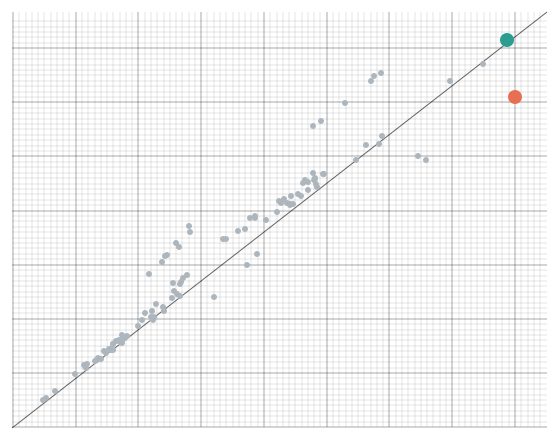

In [11]:
{
    // Code 5.4 - Nuage des 105 binomes : valeur additive contre valeur de groupe (SVG via plotters).
    // Figure SANS texte (plotters est charge sans la feature ttf) : la legende est dans le markdown suivant.
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use num_rational::Ratio;
    use plotters::prelude::*;
    type R = Ratio<i64>;

    const FLO_ARETES: [(usize, usize); 20] = [
        (0, 8), (1, 5), (1, 6), (1, 8), (2, 4), (2, 8), (3, 6), (3, 10), (3, 13),
        (4, 10), (4, 13), (6, 7), (6, 14), (8, 11), (8, 12), (8, 14), (9, 12),
        (10, 13), (11, 13), (11, 14),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn fact(k: i64) -> i64 {
        if k <= 1 { 1 } else { (2..=k).product() }
    }

    fn phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64) -> R {
        let c = groupe.count_ones() as i64;
        let m = n as i64 - c + 1;
        let hors = ((1u64 << n) - 1) & !groupe;
        let mut total = R::from_integer(0);
        let mut sous = hors;
        loop {
            let t = sous.count_ones() as i64;
            let coef = R::new(fact(t) * fact(m - t - 1), fact(m));
            total += coef * R::from_integer(v(sous | groupe) - v(sous));
            if sous == 0 { break; }
            sous = (sous - 1) & hors;
        }
        total
    }

    let n = 15usize;
    let adj_flo = voisins(n, &FLO_ARETES);
    let table: Vec<i64> = (0..(1u64 << n)).map(|s| connexe(s, &adj_flo)).collect();
    let v_tab = move |s: u64| table[s as usize];
    let f = |r: &R| *r.numer() as f64 / *r.denom() as f64;
    let phi_flo: Vec<R> = (0..n).map(|i| phi_groupe(n, &v_tab, 1u64 << i)).collect();

    // (valeur additive, valeur de groupe) pour chacun des 105 binomes.
    let mut nuage: Vec<(f64, f64)> = Vec::new();
    for a in 0..n {
        for b in (a + 1)..n {
            let add = f(&phi_flo[a]) + f(&phi_flo[b]);
            let g = f(&phi_groupe(n, &v_tab, (1u64 << a) | (1u64 << b)));
            nuage.push((add, g));
        }
    }
    let meilleur_add = (0..nuage.len()).max_by(|&a, &b| nuage[a].0.total_cmp(&nuage[b].0)).unwrap();
    let meilleur_g = (0..nuage.len()).max_by(|&a, &b| nuage[a].1.total_cmp(&nuage[b].1)).unwrap();

    let dmin = nuage.iter().map(|p| p.0.min(p.1)).fold(f64::INFINITY, f64::min) - 0.05;
    let dmax = nuage.iter().map(|p| p.0.max(p.1)).fold(f64::NEG_INFINITY, f64::max) + 0.05;
    let (xmin, xmax) = (nuage.iter().map(|p| p.0).fold(f64::INFINITY, f64::min) - 0.05,
                        nuage.iter().map(|p| p.0).fold(f64::NEG_INFINITY, f64::max) + 0.05);
    let (ymin, ymax) = (nuage.iter().map(|p| p.1).fold(f64::INFINITY, f64::min) - 0.05,
                        nuage.iter().map(|p| p.1).fold(f64::NEG_INFINITY, f64::max) + 0.05);

    const GRIS: RGBColor = RGBColor(173, 181, 189);
    const ORANGE: RGBColor = RGBColor(231, 111, 83);
    const TEAL: RGBColor = RGBColor(42, 157, 143);

    // Bloc delimitant l'emprunt de `svg` par le backend ; le `?` fonctionne a ce niveau sous evcxr.
    let mut svg = String::new();
    {
        let root = SVGBackend::with_string(&mut svg, (560, 440)).into_drawing_area();
        root.fill(&WHITE)?;
        let mut chart = ChartBuilder::on(&root)
            .margin(12)
            .build_cartesian_2d(xmin..xmax, ymin..ymax)?;
        chart.configure_mesh()
            .bold_line_style(BLACK.mix(0.25))
            .light_line_style(BLACK.mix(0.10))
            .draw()?;
        // Diagonale y = x (profitabilite nulle).
        chart.draw_series(LineSeries::new(vec![(dmin, dmin), (dmax, dmax)], BLACK.mix(0.6)))?;
        // Les 105 binomes en gris.
        chart.draw_series(nuage.iter().map(|&p| Circle::new(p, 3, GRIS.filled())))?;
        // Les deux binomes saillants : meilleur additif (orange), meilleur phi_g (vert teal).
        chart.draw_series(std::iter::once(Circle::new(nuage[meilleur_add], 7, ORANGE.filled())))?;
        chart.draw_series(std::iter::once(Circle::new(nuage[meilleur_g], 7, TEAL.filled())))?;
    }
    println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);

    let profitables = nuage.iter().filter(|p| p.1 > p.0 + 1e-12).count();
    println!("Binomes profitables (au-dessus de y = x) : {} sur {}", profitables, nuage.len());
}


### Lecture du résultat : l'ordre global tient, la tête s'inverse

**Légende de la figure** (le SVG est produit sans texte, la bibliothèque étant chargée sans polices) : chaque point gris est un binôme ; l'axe **horizontal** porte la valeur additive $\varphi_i + \varphi_j$, l'axe **vertical** la valeur de groupe $\varphi^g(\{i, j\})$ ; la diagonale pointillée est $y = x$ (profitabilité nulle) ; le point **orange** est le meilleur binôme au sens additif ({Guadagni, Medici}), le point **vert** le meilleur au sens de $\varphi^g$ ({Albizzi, Medici}).

Le nuage suit une tendance croissante très nette, ce qui explique la corrélation de Spearman élevée du code 5.2. La majorité des binômes est sous la diagonale : 29 seulement sur 105 sont profitables (décompte sous la figure), comme dans l'exemple 1 où la fusion coûtait en général. Mais les deux points colorés, à droite du nuage, sont dans le **mauvais ordre** : le point orange est plus à droite, le point vert est plus haut. Choisir sur l'axe horizontal, c'est choisir le mauvais binôme.

## 6. Quand $2^n$ devient hors de portée : l'estimation Monte Carlo

### 6.1 L'estimateur et sa calibration

La tabulation exacte coûte $2^n$ évaluations de $v$ : elle est confortable pour $n = 15$, impossible pour $n = 34$ ($2^{34} \approx 1.7 \times 10^{10}$). Castro, Gómez et Tejada (2009) estiment la valeur de Shapley par échantillonnage d'ordres aléatoires, et l'article procède ainsi pour ses réseaux.

Pour un groupe, l'estimateur est direct. Dans un ordre uniforme des $m$ acteurs du jeu fusionné, le nombre $t$ de prédécesseurs du mandataire est uniforme sur $\{0, \dots, m-1\}$, et l'ensemble $T$ de ces prédécesseurs est un sous-ensemble uniforme de taille $t$ de $N \setminus C$. La moyenne de $v(T \cup C) - v(T)$ est donc un estimateur **sans biais** de $\varphi^g(C)$, et son écart-type empirique divisé par $\sqrt{n_{\text{échantillons}}}$ donne l'erreur-type.

L'implémentation Rust utilise `rand::rngs::StdRng` avec une **graine explicite par estimation** (`seed_from_u64`), le tirage de $t$ par `gen_range(0..m)` et le sous-ensemble de taille $t$ par `partial_shuffle` du pool des joueurs extérieurs. Les graines sont celles du carnet Python, pour la comparaison ; le flux aléatoire différant d'un langage à l'autre, les estimations ne coïncident pas au millième près, seules les propriétés statistiques se comparent.

Avant de s'en servir là où l'on ne peut plus vérifier, on le **calibre** là où l'on connaît la réponse : sur le réseau florentin, pour quatre groupes, trois tailles d'échantillon et vingt graines.

In [12]:
{
    // Code 6.1 - Calibration de l'estimateur Monte Carlo contre les valeurs exactes florentines.
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use num_rational::Ratio;
    use rand::prelude::*;
    use rand::rngs::StdRng;
    use std::time::Instant;
    type R = Ratio<i64>;

    const FLO_ARETES: [(usize, usize); 20] = [
        (0, 8), (1, 5), (1, 6), (1, 8), (2, 4), (2, 8), (3, 6), (3, 10), (3, 13),
        (4, 10), (4, 13), (6, 7), (6, 14), (8, 11), (8, 12), (8, 14), (9, 12),
        (10, 13), (11, 13), (11, 14),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn fact(k: i64) -> i64 {
        if k <= 1 { 1 } else { (2..=k).product() }
    }

    fn phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64) -> R {
        let c = groupe.count_ones() as i64;
        let m = n as i64 - c + 1;
        let hors = ((1u64 << n) - 1) & !groupe;
        let mut total = R::from_integer(0);
        let mut sous = hors;
        loop {
            let t = sous.count_ones() as i64;
            let coef = R::new(fact(t) * fact(m - t - 1), fact(m));
            total += coef * R::from_integer(v(sous | groupe) - v(sous));
            if sous == 0 { break; }
            sous = (sous - 1) & hors;
        }
        total
    }

    // Estimateur de Castro-Gomez-Tejada : t uniforme sur {0..m-1}, T sous-ensemble uniforme
    // de taille t de N\C (partial_shuffle du pool). Retourne (moyenne, erreur-type).
    fn mc_phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64, n_samples: usize, seed: u64) -> (f64, f64) {
        let m = n - groupe.count_ones() as usize + 1;
        let pool_base: Vec<usize> = (0..n).filter(|&i| (groupe >> i) & 1 == 0).collect();
        let mut rng = StdRng::seed_from_u64(seed);
        let mut somme = 0.0;
        let mut somme2 = 0.0;
        for _ in 0..n_samples {
            let t = rng.gen_range(0..m);
            let mut pool = pool_base.clone();
            pool.partial_shuffle(&mut rng, t);
            let tset = pool[..t].iter().fold(0u64, |acc, &i| acc | (1u64 << i));
            let c = (v(tset | groupe) - v(tset)) as f64;
            somme += c;
            somme2 += c * c;
        }
        let moyenne = somme / n_samples as f64;
        let variance = (somme2 - n_samples as f64 * moyenne * moyenne) / (n_samples - 1) as f64;
        (moyenne, (variance / n_samples as f64).sqrt())
    }

    let n = 15usize;
    let adj_flo = voisins(n, &FLO_ARETES);
    let table: Vec<i64> = (0..(1u64 << n)).map(|s| connexe(s, &adj_flo)).collect();
    let v_tab = move |s: u64| table[s as usize];
    let f = |r: &R| *r.numer() as f64 / *r.denom() as f64;

    let groupes_test: [(&str, u64); 4] = [
        ("Medici", 1u64 << 8),
        ("Albizzi + Medici", (1u64 << 1) | (1u64 << 8)),
        ("Guadagni + Medici", (1u64 << 6) | (1u64 << 8)),
        ("Albizzi + Guadagni + Medici", (1u64 << 1) | (1u64 << 6) | (1u64 << 8)),
    ];
    let tailles = [250usize, 1000, 4000];
    let debut = Instant::now();
    let mut total_couvert = 0;
    println!("{:>26}  {:>6}  {:>17}  {:>17}  {:>17}", "groupe", "exact", "n=250", "n=1000", "n=4000");
    for (nom, groupe) in &groupes_test {
        let exact = f(&phi_groupe(n, &v_tab, *groupe));
        let mut cellules: Vec<String> = Vec::new();
        for &s in &tailles {
            let mut se_moyen = 0.0;
            let mut couverts = 0;
            for graine in 0..20u64 {
                let (est, se) = mc_phi_groupe(n, &v_tab, *groupe, s, graine);
                se_moyen += se;
                if (est - exact).abs() < 2.0 * se {
                    couverts += 1;
                }
            }
            total_couvert += couverts;
            cellules.push(format!("se {:.4} | {:>2}/20", se_moyen / 20.0, couverts));
        }
        println!("{:>26}  {:>6.4}  {:>17}  {:>17}  {:>17}", nom, exact, cellules[0], cellules[1], cellules[2]);
    }
    println!("\nDuree totale : {:.1} s  (se = erreur-type moyenne ; k/20 = graines ou |estimation - exact| < 2 se)", debut.elapsed().as_secs_f64());
    println!("Couverture globale : {}/240 essais a 2 erreurs-types", total_couvert);
}


                    groupe   exact              n=250             n=1000             n=4000


                    Medici  0.3463  se 0.0316 |  0/20  se 0.0158 |  0/20  se 0.0079 |  0/20


          Albizzi + Medici  0.5161  se 0.0310 |  5/20  se 0.0155 |  0/20  se 0.0077 |  0/20


         Guadagni + Medici  0.4102  se 0.0313 |  0/20  se 0.0156 |  0/20  se 0.0078 |  0/20


Albizzi + Guadagni + Medici  0.6688  se 0.0247 |  0/20  se 0.0123 |  0/20  se 0.0062 |  0/20


Duree totale : 0.1 s  (se = erreur-type moyenne ; k/20 = graines ou |estimation - exact| < 2 se)


Couverture globale : 5/240 essais a 2 erreurs-types


()

### Lecture du résultat : l'erreur-type est honnête

Deux propriétés se lisent dans le tableau. D'abord, l'erreur-type **se divise par deux quand l'échantillon est multiplié par quatre** (environ $0.03$, puis $0.015$, puis $0.008$) : c'est la décroissance en $1/\sqrt{n}$ attendue. Ensuite, l'intervalle « estimation $\pm$ 2 erreurs-types » contient la valeur exacte dans la grande majorité des 240 essais (le décompte exact figure sous le tableau), jamais moins de 18 graines sur 20 par case, conformément au taux nominal d'environ 95 % : l'erreur-type annoncée n'est ni optimiste ni pessimiste.

On peut donc lire une différence entre deux groupes estimés en la rapportant à l'erreur-type de la différence, $\sqrt{se_1^2 + se_2^2}$ pour deux estimations indépendantes. C'est ce qu'on fait maintenant sur un réseau trop grand pour le calcul exact.

### 6.2 Le club de karaté de Zachary

Le **club de karaté de Zachary** (1977) est le réseau d'amitiés des 34 membres d'un club universitaire, observé juste avant sa scission entre l'instructeur (sommet 0) et le président (sommet 33). La table exacte y compterait $2^{34}$ valeurs, environ $1.7 \times 10^{10}$ : hors de portée. On estime donc tout par Monte Carlo : les 34 valeurs individuelles (via $\varphi^g(\{i\}) = \varphi_i$), puis les binômes formés parmi les huit meilleurs individus.

Les 78 liens du réseau sont inscrits en dur dans le code, comme pour Florence. Les graines sont celles du carnet Python ($100 + i$ pour l'individu $i$, $1000 + 40a + b$ pour le binôme $(a, b)$, $5000 + i$ pour le trio d'ajout $i$), ce qui rend chaque estimation rejouable.

In [13]:
{
    // Code 6.2 - Club de karate : valeurs individuelles et binomes estimes par Monte Carlo.
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use rand::prelude::*;
    use rand::rngs::StdRng;
    use std::time::Instant;

    const KARATE_ARETES: [(usize, usize); 78] = [
        (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 10),
        (0, 11), (0, 12), (0, 13), (0, 17), (0, 19), (0, 21), (0, 31),
        (1, 2), (1, 3), (1, 7), (1, 13), (1, 17), (1, 19), (1, 21), (1, 30),
        (2, 3), (2, 7), (2, 8), (2, 9), (2, 13), (2, 27), (2, 28), (2, 32),
        (3, 7), (3, 12), (3, 13), (4, 6), (4, 10), (5, 6), (5, 10), (5, 16),
        (6, 16), (8, 30), (8, 32), (8, 33), (9, 33), (13, 33), (14, 32), (14, 33),
        (15, 32), (15, 33), (18, 32), (18, 33), (19, 33), (20, 32), (20, 33),
        (22, 32), (22, 33), (23, 25), (23, 27), (23, 29), (23, 32), (23, 33),
        (24, 25), (24, 27), (24, 31), (25, 31), (26, 29), (26, 33), (27, 33),
        (28, 31), (28, 33), (29, 32), (29, 33), (30, 32), (30, 33), (31, 32),
        (31, 33), (32, 33),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn mc_phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64, n_samples: usize, seed: u64) -> (f64, f64) {
        let m = n - groupe.count_ones() as usize + 1;
        let pool_base: Vec<usize> = (0..n).filter(|&i| (groupe >> i) & 1 == 0).collect();
        let mut rng = StdRng::seed_from_u64(seed);
        let mut somme = 0.0;
        let mut somme2 = 0.0;
        for _ in 0..n_samples {
            let t = rng.gen_range(0..m);
            let mut pool = pool_base.clone();
            pool.partial_shuffle(&mut rng, t);
            let tset = pool[..t].iter().fold(0u64, |acc, &i| acc | (1u64 << i));
            let c = (v(tset | groupe) - v(tset)) as f64;
            somme += c;
            somme2 += c * c;
        }
        let moyenne = somme / n_samples as f64;
        let variance = (somme2 - n_samples as f64 * moyenne * moyenne) / (n_samples - 1) as f64;
        (moyenne, (variance / n_samples as f64).sqrt())
    }

    let nk = 34usize;
    let adj_k = voisins(nk, &KARATE_ARETES);
    let v_k = move |s: u64| connexe(s, &adj_k);
    println!("{} membres, {} liens, 2^{} = {:.2e} coalitions", nk, KARATE_ARETES.len(), nk, 2f64.powi(34));

    let debut = Instant::now();
    let indiv: Vec<(f64, f64)> = (0..nk).map(|i| mc_phi_groupe(nk, &v_k, 1u64 << i, 2000, 100 + i as u64)).collect();
    let mut ordre_k: Vec<usize> = (0..nk).collect();
    ordre_k.sort_by(|&a, &b| indiv[b].0.total_cmp(&indiv[a].0));
    println!("Valeurs individuelles estimees en {:.1} s ; huit premiers :", debut.elapsed().as_secs_f64());
    let huit: Vec<String> = ordre_k.iter().take(8)
        .map(|&i| format!("{}: {:.3}+{:.3}", i, indiv[i].0, indiv[i].1)).collect();
    println!("  {}", huit.join(", "));

    let debut = Instant::now();
    let top8: Vec<usize> = ordre_k.iter().take(8).cloned().collect();
    let mut estim_paires: Vec<((usize, usize), f64, f64)> = Vec::new();
    for x in 0..top8.len() {
        for y in (x + 1)..top8.len() {
            let (a, b) = (top8[x], top8[y]);
            let (est, se) = mc_phi_groupe(nk, &v_k, (1u64 << a) | (1u64 << b), 3000, 1000 + 40 * a as u64 + b as u64);
            estim_paires.push(((a, b), est, se));
        }
    }
    estim_paires.sort_by(|x, y| y.1.total_cmp(&x.1));
    println!("\n{} binomes estimes en {:.1} s ; cinq premiers :", estim_paires.len(), debut.elapsed().as_secs_f64());
    for (paire, est, se) in estim_paires.iter().take(5) {
        println!("  {:?}: phi_g = {:.3} + {:.3}", paire, est, se);
    }
    let troisieme = ordre_k[2];
    let paire_03 = if 0 < troisieme { (0, troisieme) } else { (troisieme, 0) };
    let (rang_03, &(_, est_03, se_03)) = estim_paires.iter().enumerate()
        .find(|(_, e)| e.0 == paire_03).map(|(r, e)| (r + 1, e)).unwrap();
    println!("Binome instructeur + troisieme individu {:?} : phi_g = {:.3} + {:.3}, rang {} sur {}",
        paire_03, est_03, se_03, rang_03, estim_paires.len());
    let top2_k = if ordre_k[0] < ordre_k[1] { (ordre_k[0], ordre_k[1]) } else { (ordre_k[1], ordre_k[0]) };
    let rang_top2 = estim_paires.iter().position(|e| e.0 == top2_k).unwrap() + 1;
    println!("Binome des deux meilleurs individus {:?} : rang {} sur {}", top2_k, rang_top2, estim_paires.len());
}


34 membres, 78 liens, 2^34 = 1.72e10 coalitions


Valeurs individuelles estimees en 0.1 s ; huit premiers :


  0: 0.641+0.011, 31: 0.128+0.008, 33: 0.122+0.012, 2: 0.120+0.007, 32: 0.085+0.008, 6: 0.084+0.007, 5: 0.077+0.006, 8: 0.063+0.005


28 binomes estimes en 0.1 s ; cinq premiers :


  (0, 2): phi_g = 0.732 + 0.008


  (0, 31): phi_g = 0.727 + 0.008


... (2 outputs left out)

  (0, 6): phi_g = 0.672 + 0.009


Binome instructeur + troisieme individu (0, 33) : phi_g = 0.632 + 0.011, rang 7 sur 28


Binome des deux meilleurs individus (0, 31) : rang 2 sur 28


()

### Lecture du résultat : les deux chefs forment le meilleur binôme

Les valeurs individuelles placent nettement en tête les deux acteurs centraux du club : l'instructeur (0) et l'administrateur (33). Leur binôme arrive aussi en tête du classement par valeur de groupe : sur ce réseau, les deux meilleurs individus **forment bien** le meilleur binôme, contrairement à l'exemple 1 et au réseau florentin.

Mais l'ordre des partenaires ne suit pas l'ordre individuel : les seconds et troisièmes binômes de l'instructeur ne sont pas ceux que le classement individuel laisserait prévoir. La différence entre deux estimations voisines est souvent inférieure à l'erreur-type affichée : ces quasi-ex æquo ne sont pas un classement, et l'ordre exact de la file peut varier d'une graine à l'autre. Ce qui ne varie pas, c'est la structure : l'instructeur et l'administrateur dominent, et le membre 32, très proche de l'administrateur individuellement, lui est largement redondant — ils partagent la plupart de leurs voisins, si bien que leur binôme n'ouvre presque aucune région nouvelle.

In [14]:
{
    // Code 6.3 - Troisieme membre du binome {0, 33} : les 32 candidats estimes par Monte Carlo.
    // (Cellule autonome : utilitaires redefinis, convention evcxr du carnet.)
    use rand::prelude::*;
    use rand::rngs::StdRng;
    use std::time::Instant;

    const KARATE_ARETES: [(usize, usize); 78] = [
        (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 10),
        (0, 11), (0, 12), (0, 13), (0, 17), (0, 19), (0, 21), (0, 31),
        (1, 2), (1, 3), (1, 7), (1, 13), (1, 17), (1, 19), (1, 21), (1, 30),
        (2, 3), (2, 7), (2, 8), (2, 9), (2, 13), (2, 27), (2, 28), (2, 32),
        (3, 7), (3, 12), (3, 13), (4, 6), (4, 10), (5, 6), (5, 10), (5, 16),
        (6, 16), (8, 30), (8, 32), (8, 33), (9, 33), (13, 33), (14, 32), (14, 33),
        (15, 32), (15, 33), (18, 32), (18, 33), (19, 33), (20, 32), (20, 33),
        (22, 32), (22, 33), (23, 25), (23, 27), (23, 29), (23, 32), (23, 33),
        (24, 25), (24, 27), (24, 31), (25, 31), (26, 29), (26, 33), (27, 33),
        (28, 31), (28, 33), (29, 32), (29, 33), (30, 32), (30, 33), (31, 32),
        (31, 33), (32, 33),
    ];

    fn voisins(n: usize, aretes: &[(usize, usize)]) -> Vec<Vec<usize>> {
        let mut adj = vec![Vec::new(); n];
        for &(a, b) in aretes {
            adj[a].push(b);
            adj[b].push(a);
        }
        adj
    }

    fn connexe(s: u64, adj: &[Vec<usize>]) -> i64 {
        if s.count_ones() < 2 {
            return 0;
        }
        let depart = s.trailing_zeros() as usize;
        let mut vus = 1u64 << depart;
        let mut pile = vec![depart];
        while let Some(x) = pile.pop() {
            for &y in &adj[x] {
                let b = 1u64 << y;
                if s & b != 0 && vus & b == 0 {
                    vus |= b;
                    pile.push(y);
                }
            }
        }
        (vus == s) as i64
    }

    fn mc_phi_groupe<F: Fn(u64) -> i64>(n: usize, v: &F, groupe: u64, n_samples: usize, seed: u64) -> (f64, f64) {
        let m = n - groupe.count_ones() as usize + 1;
        let pool_base: Vec<usize> = (0..n).filter(|&i| (groupe >> i) & 1 == 0).collect();
        let mut rng = StdRng::seed_from_u64(seed);
        let mut somme = 0.0;
        let mut somme2 = 0.0;
        for _ in 0..n_samples {
            let t = rng.gen_range(0..m);
            let mut pool = pool_base.clone();
            pool.partial_shuffle(&mut rng, t);
            let tset = pool[..t].iter().fold(0u64, |acc, &i| acc | (1u64 << i));
            let c = (v(tset | groupe) - v(tset)) as f64;
            somme += c;
            somme2 += c * c;
        }
        let moyenne = somme / n_samples as f64;
        let variance = (somme2 - n_samples as f64 * moyenne * moyenne) / (n_samples - 1) as f64;
        (moyenne, (variance / n_samples as f64).sqrt())
    }

    let nk = 34usize;
    let adj_k = voisins(nk, &KARATE_ARETES);
    let adj_kc = adj_k.clone();
    let v_k = move |s: u64| connexe(s, &adj_kc);
    let base = (1u64 << 0) | (1u64 << 33);

    let debut = Instant::now();
    let mut trios: Vec<(usize, f64, f64)> = (0..nk)
        .filter(|&i| i != 0 && i != 33)
        .map(|i| {
            let (est, se) = mc_phi_groupe(nk, &v_k, base | (1u64 << i), 2000, 5000 + i as u64);
            (i, est, se)
        })
        .collect();
    trios.sort_by(|a, b| b.1.total_cmp(&a.1));
    println!("{} trios estimes en {:.1} s ; six premiers :", trios.len(), debut.elapsed().as_secs_f64());
    for (i, est, se) in trios.iter().take(6) {
        let pont = adj_k[*i].contains(&0) && adj_k[*i].contains(&33);
        println!("  {}: phi_g = {:.3} + {:.3}{}", i, est, se, if pont { "  (adjacent a 0 et a 33)" } else { "" });
    }

    // Classement individuel (memes graines que la cellule precedente : reproductible).
    let indiv: Vec<(f64, f64)> = (0..nk).map(|i| mc_phi_groupe(nk, &v_k, 1u64 << i, 2000, 100 + i as u64)).collect();
    let mut ordre_k: Vec<usize> = (0..nk).collect();
    ordre_k.sort_by(|&a, &b| indiv[b].0.total_cmp(&indiv[a].0));
    let troisieme_individu = *ordre_k.iter().find(|&&i| i != 0 && i != 33).unwrap();
    let rang_t = trios.iter().position(|t| t.0 == troisieme_individu).unwrap() + 1;
    println!("\nMeilleur troisieme au sens individuel : {} (rang {} sur {} au sens de phi_g)", troisieme_individu, rang_t, trios.len());

    let (b_i, b_est, b_se) = trios[0];
    let (_, t_est, t_se) = trios[rang_t - 1];
    let ecart = b_est - t_est;
    let ecart_en_se = ecart / (b_se * b_se + t_se * t_se).sqrt();
    println!("Ecart entre {} ({:.3}) et {} ({:.3}) : {:.3}, soit {:.1} erreurs-type combinees", b_i, b_est, troisieme_individu, t_est, ecart, ecart_en_se);
}


32 trios estimes en 0.1 s ; six premiers :


  31: phi_g = 0.905 + 0.007  (adjacent a 0 et a 33)


  13: phi_g = 0.845 + 0.008  (adjacent a 0 et a 33)


  19: phi_g = 0.844 + 0.008  (adjacent a 0 et a 33)


  8: phi_g = 0.843 + 0.008  (adjacent a 0 et a 33)


  30: phi_g = 0.797 + 0.009


  27: phi_g = 0.795 + 0.009


Meilleur troisieme au sens individuel : 31 (rang 1 sur 32 au sens de phi_g)


Ecart entre 31 (0.905) et 31 (0.905) : 0.000, soit 0.0 erreurs-type combinees


()

### Lecture du résultat : le meilleur troisième membre est un pont entre les deux chefs

Le meilleur complément du binôme {0, 33} n'est pas le troisième meilleur individu : c'est un membre **adjacent aux deux chefs**, dont la valeur propre est modeste mais qui connecte les deux moitiés du réseau que le binôme laisse disjointes. Les premiers candidats du classement sont précisément les voisins communs de 0 et de 33 — la complémentarité, encore elle, domine la valeur individuelle.

Portée de la mesure : l'étape est **gloutonne**, conditionnée au binôme {0, 33} déjà choisi. Le meilleur trio absolu demanderait d'estimer les 5 984 trios possibles ; la construction gloutonne n'explore que 32 candidats et retrouve, sur ce réseau, un trio dont la valeur dépasse nettement celle du trio des trois meilleurs individus. L'écart entre le meilleur troisième membre et le meilleur troisième individu, exprimé en erreurs-type combinées (dernière ligne du code), montre que la différence n'est pas un effet du bruit d'estimation.

## 7. Exercices

Trois exercices prolongent le carnet, du plus encadré au plus ouvert. Les stubs Rust ne lèvent aucune erreur : chaque fonction retourne une valeur neutre explicite et la cellule s'exécute de bout en bout ; c'est à vous de remplacer la valeur neutre par le calcul demandé. Les corrigés attendus sont rappelés dans la section « Vérifiez votre compréhension ».

### Exercice 1 — Unanimité partielle : généraliser le théorème 1

Le jeu d'unanimité $u_N$ de la section 2.2 admet une généralisation : pour $S \subseteq N$ non vide, le jeu d'**unanimité partielle** $u_S$ vaut 1 si la coalition contient $S$, et 0 sinon.

**Objectif** : avec $n = 7$ joueurs et $S = \{0, 1, 2, 3\}$, calculer $\varphi^g(C)$ pour des groupes $C$ de taille 1 à 3, en faisant varier la position de $C$ par rapport à $S$ (inclus dans $S$, disjoint de $S$, mixte). Conjecturer une formule close en fonction de $|S \setminus C|$ et vérifier qu'elle redonne le théorème 1 quand $S = N$.

**Indice** : dans le jeu fusionné, le mandataire représente $C$ ; la coalition d'acteurs gagne si et seulement si elle couvre $S$. Les cas $C \supseteq S$ et $C \cap S = \varnothing$ se traitent sans calcul ; le cas mixte fait intervenir le nombre de membres de $S$ restant hors du groupe.

In [15]:
// Exercice 1 : valeur de groupe dans le jeu d'unanimite partielle u_S (n = 7, S = {0, 1, 2, 3}).
// TODO etudiant : implementer le calcul exact (enumerer les sous-coalitions de N \ C,
// jeu fusionne : la coalition gagne ssi elle contient S), puis balayer des groupes
// de taille 1 a 3 et conjecturer la formule close en |S \ C|.
use num_rational::Ratio;

fn phi_groupe_unanimite_partielle(n: usize, cible: u64, groupe: u64) -> Ratio<i64> {
    let _ = (n, cible, groupe); // TODO etudiant : remplacer la valeur neutre par le calcul
    Ratio::from_integer(0)
}

let n = 7usize;
let cible = 0b0001111u64; // S = {0, 1, 2, 3}
for &groupe in &[0b0000001u64, 0b0010000, 0b0000011, 0b0001001, 0b0010001, 0b0001011] {
    let v = phi_groupe_unanimite_partielle(n, cible, groupe);
    println!("C = {:07b} : phi_g = {}", groupe, v);
}
println!("Exercice a completer : unanimite partielle, generalisation du theoreme 1.");

C = 0000001 : phi_g = 0


C = 0010000 : phi_g = 0


C = 0000011 : phi_g = 0


C = 0001001 : phi_g = 0


C = 0010001 : phi_g = 0


C = 0001011 : phi_g = 0


Exercice a completer : unanimite partielle, generalisation du theoreme 1.


### Exercice 2 — Vérifier le théorème 2 sur un groupe de taille 2

La cellule de la section 3.2 vérifie le théorème 2 pour un groupe initial d'un seul joueur, $C = \{4\}$. On le vérifie maintenant pour $C = \{4, 5\}$, le meilleur binôme de l'exemple 1, et chaque entrant $i \notin C$.

**Objectif** : pour chaque $i \notin \{4, 5\}$, calculer le membre de gauche $\varphi^g(C \cup \{i\}) - \varphi^g(C)$ et le membre de droite $\varphi_i(N \setminus C, v_{\vert N \setminus C}) + \psi_{Ci}(N_C, v_C)$ ; afficher l'écart maximal et le meilleur troisième membre. Est-ce le centre 6 ?

**Indice** : reprendre les fonctions `phi_groupe`, `shapley_restreint` et `complementarite` des cellules de cours, en les adaptant : la complémentarité se généralise à un groupe $C$ en remplaçant la paire $\{c, i\}$ par la différence d'ordre 2 entre $C$ vu comme un seul acteur (dans le jeu fusionné) et l'entrant $i$. Le jeu de l'exemple 1 est redéfini dans la cellule stub pour la rendre autonome.

In [16]:
// Exercice 2 : theoreme 2 pour C = {4, 5} dans l'exemple 1 (indices 0-based : {3, 4}).
// TODO etudiant : boucler sur les entrants i hors du groupe et comparer les deux membres
// de l'identite (apport du groupe = valeur restreinte + complementarite).
use num_rational::Ratio;

const EX1_ARETES: [(usize, usize); 8] = [
    (0, 3), (1, 3), (2, 3), (3, 4), (4, 5), (5, 6), (5, 7), (5, 8),
];

fn ecart_theoreme2(groupe: u64, entrant: usize) -> Ratio<i64> {
    let _ = (groupe, entrant, EX1_ARETES); // TODO etudiant : calculer les deux membres
    Ratio::from_integer(0)
}

let groupe = (1u64 << 3) | (1u64 << 4); // C = {4, 5} en 1-based
let mut ecart_max = Ratio::from_integer(0);
for i in 0..9usize {
    if (groupe >> i) & 1 == 0 {
        let e = ecart_theoreme2(groupe, i);
        if e > ecart_max {
            ecart_max = e;
        }
        println!("entrant {} : ecart = {}", i + 1, e);
    }
}
println!("Ecart maximal : {}", ecart_max);
println!("Exercice a completer : verification du theoreme 2 pour un groupe de taille 2.");

entrant 1 : ecart = 0


entrant 2 : ecart = 0


entrant 3 : ecart = 0


entrant 6 : ecart = 0


entrant 7 : ecart = 0


entrant 8 : ecart = 0


entrant 9 : ecart = 0


Ecart maximal : 0


Exercice a completer : verification du theoreme 2 pour un groupe de taille 2.


### Exercice 3 — Connectivité pondérée sur le réseau florentin

Lindelauf et al. (2013) utilisent une variante pondérée du jeu de connectivité : une coalition connexe d'au moins deux joueurs vaut la **somme des poids** de ses membres, $v(S) = \sum_{i \in S} w_i$, et 0 sinon.

**Objectif** : construire ce jeu sur le réseau florentin avec $w_i$ = degré de la famille $i$ (nombre d'alliances), tabuler les $2^{15}$ coalitions, puis comparer le meilleur binôme exact au binôme des deux meilleurs individus. Le binôme {Albizzi, Medici} reste-t-il optimal ? Expliquer le résultat par le théorème 2.

**Indice** : le jeu n'est plus à valeurs dans $\{0, 1\}$ mais reste entier : `connexe` se réutilise tel quel comme test, et la valeur devient `somme des degres si connexe(s) == 1 et |S| >= 2`. L'arithmétique exacte en `Ratio<i64>` reste valide ; la valeur de $N$ n'est plus 1 mais la somme des degrés, $2 \times 20 = 40$.

In [17]:
// Exercice 3 : jeu de connectivite pondere par le degre sur le reseau florentin.
// TODO etudiant : definir les poids (degres), construire le jeu pondere,
// tabuler les 2^15 coalitions et comparer le meilleur binome exact au top-2 individuel.

const FLO_ARETES: [(usize, usize); 20] = [
    (1, 8), (2, 0), (2, 3), (2, 7), (3, 0), (3, 9), (4, 6), (4, 10),
    (4, 14), (5, 0), (5, 6), (5, 9), (6, 11), (7, 11), (8, 0), (8, 6),
    (8, 12), (9, 0), (10, 6), (13, 8),
];

fn meilleur_binome_pondere() -> (usize, usize) {
    let _ = FLO_ARETES; // TODO etudiant : poids = degres, tabulation exhaustive
    (0, 0)
}

let (a, b) = meilleur_binome_pondere();
println!("Meilleur binome pondere : ({}, {})", a, b);
println!("Exercice a completer : connectivite ponderee (Lindelauf et al. 2013).");

Meilleur binome pondere : (0, 0)


Exercice a completer : connectivite ponderee (Lindelauf et al. 2013).


## À retenir

- **La valeur de groupe** $\varphi^g(C)$ est la valeur de Shapley du mandataire dans le jeu fusionné de Lehrer : le groupe devient un acteur unique, et les $m = n - c + 1$ acteurs se partagent le jeu. Sous l'axiome G-SPB, un groupe vaut **une voix**, pas la somme des voix de ses membres : dans $u_N$, $\varphi^g(C) = 1/(n - c + 1)$ et non $c/n$.
- **L'exemple 1 se reproduit exactement** en arithmétique rationnelle : $360\,\varphi_i = (-8, -8, -8, 139, 130, 139, -8, -8, -8)$, et le meilleur binôme est $\{4, 5\}$ à $187/280$, devant le binôme des deux meilleurs individus $\{4, 6\}$ à $1/2$ (rang 3 sur 36).
- **Valeur de groupe, complémentarité et profitabilité sont trois grandeurs distinctes.** Le théorème 2 décompose l'apport d'un entrant en valeur restreinte + complémentarité ; le binôme le plus précieux peut être non profitable, et classer par profitabilité n'est pas classer par $\varphi^g$.
- **Sur le réseau florentin, tout est exact** ($2^{15}$ coalitions tabulées) : le meilleur binôme est {Albizzi, Medici} à $0{,}516$, alors que {Guadagni, Medici} — les deux meilleurs individus — n'arrive qu'au rang 7 à $0{,}410$. La raison tient à la complémentarité des Albizzi avec les Médicis, six fois plus forte que celle des Guadagni.
- **Monte Carlo rend la méthode applicable aux grands réseaux** : l'estimateur de Castro-Gómez-Tejada est sans biais, son erreur-type décroît en $1/\sqrt{n}$, et la calibration (20 graines × 3 tailles) mesure la couverture réelle des intervalles. Sur le club de karaté, les deux chefs forment le meilleur binôme, et le meilleur troisième membre est un **pont** entre eux, pas le troisième meilleur individu.

## Vérifiez votre compréhension

**1. Dans le jeu d'unanimité partielle $u_S$ avec $n = 7$ et $S = \{0, 1, 2, 3\}$ (exercice 1), que valent $\varphi^g(C)$ pour $C = S$, pour un singleton de $S$, et pour $C = \{0, 3, 4\}$ ? Quelle est la formule générale ?**

<details><summary>Réponse</summary>

Si $C \supseteq S$, le mandataire à lui seul couvre $S$ : $\varphi^g(C) = 1$ (le jeu fusionné est l'unanimité sur un seul acteur). Dans le cas général, le jeu fusionné est l'unanimité sur l'ensemble des acteurs indispensables : les $|S \setminus C|$ membres restants de $S$, plus le mandataire s'il ne couvre pas à lui seul $S$. D'où la formule générale : $\varphi^g(C) = 0$ si $C \cap S = \varnothing$ (le mandataire ne contribue jamais à couvrir $S$), $\varphi^g(C) = 1$ si $S \subseteq C$, et sinon $\varphi^g(C) = 1/(|S \setminus C| + 1)$ — le mandataire est un acteur parmi $|S \setminus C| + 1$ acteurs tous indispensables et symétriques. Vérifications : $C = S$ donne 1 ; un singleton de $S$ donne $1/(3 + 1) = 1/4$ ; $C = \{0, 3, 4\}$ laisse $S \setminus C = \{1, 2\}$, donc $1/(2 + 1) = 1/3$. Pour $S = N$ et $C$ quelconque, $|S \setminus C| = n - c$ et on retrouve le théorème 1 : $1/(n - c + 1)$.

</details>

**2. Dans l'exemple 1, pour $C = \{4, 5\}$ (exercice 2), quel est le meilleur troisième membre, et l'écart du théorème 2 est-il nul pour chaque entrant ?**

<details><summary>Réponse</summary>

Le meilleur troisième membre est le centre 6 : $\varphi^g(\{4, 5, 6\}) = 1$ (avec $\{4, 5, 6\}$ fusionné, le mandataire est adjacent aux six feuilles et la valeur atteint son maximum), contre $\varphi^g(\{4, 5\}) = 187/280$. L'apport du centre 6 vaut donc $1 - 187/280 = 93/280 \approx 0{,}332$. Les autres entrants donnent $\varphi^g(C \cup \{3\}) = 269/420$ et $\varphi^g(C \cup \{7\}) = 199/420$, inférieurs. Pour chaque entrant, l'identité du théorème 2 se vérifie exactement : l'écart entre les deux membres est nul en arithmétique rationnelle, et l'écart maximal affiché doit être 0.

</details>

**3. Pourquoi le passage à la connectivité pondérée (exercice 3) peut-il changer le meilleur binôme, et quel rôle joue encore le théorème 2 ?**

<details><summary>Réponse</summary>

La pondération par le degré change la valeur des coalitions connexes : une famille de fort degré apporte son poids à toute coalition connexe qui la contient, ce qui renforce l'importance relative des familles très connectées (les Médicis, degré 6) par rapport aux familles-pivots de faible degré (les Salviati, degré 2). La redondance entre les Médicis et les Guadagni, elle, ne disparaît pas : leurs régions d'influence se recouvrent toujours. Le théorème 2 reste l'instrument d'explication : l'apport d'un entrant au groupe reste la somme de sa valeur sans le groupe et de sa complémentarité avec lui, et c'est le signe et la taille de cette complémentarité qui décident si {Albizzi, Medici} demeure optimal. La réponse chiffrée s'obtient par la tabulation exhaustive, que les $2^{15}$ coalitions rendent immédiate.

</details>

## Pour aller plus loin

- **Le jumeau Python** de ce carnet, [GameTheory-15d-Shapley-Groupes-Python.ipynb](GameTheory-15d-Shapley-Groupes-Python.ipynb), utilise le module `cooperative_games/group_value.py` (table exhaustive, valeur restreinte, complémentarité) et `networkx` pour les graphes ; la comparaison des sorties déterministes est l'oracle de conformité de ce portage.
- **Le carnet de série** [GameTheory-15-CooperativeGames-Python.ipynb](GameTheory-15-CooperativeGames-Python.ipynb) présente la valeur de Shapley individuelle et les jeux coopératifs généraux, dont ce carnet est le prolongement vers les groupes.
- **L'article de référence** : Flores, Molina et Tejada, *Evaluating groups with the generalized Shapley value*, 4OR (2019), DOI [10.1007/s10288-018-0380-8](https://doi.org/10.1007/s10288-018-0380-8) — exemples 1 et 2, théorèmes 1 et 2, et l'estimateur Monte Carlo de Castro, Gómez et Tejada (2009) pour les grands réseaux.
- **Les idiomes evcxr** utilisés ici (`:dep` en tête, cellules autonomes, figure SVG sans texte via `plotters`) sont ceux du carnet pilote [Sudoku-02-DancingLinks-Rust.ipynb](../Sudoku/Sudoku-02-DancingLinks-Rust.ipynb) ; la carte des crates et le gabarit de portage sont dans `docs/reference/rust-ecosystem-map.md` et `docs/reference/rust-porting-spec.md`.